# Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay, classification_report, confusion_matrix, average_precision_score, RocCurveDisplay, PrecisionRecallDisplay
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance

from scipy.sparse import issparse
from scipy.stats import spearmanr

from xgboost import XGBClassifier

import shap

# Load Data

In [2]:
df_customer_train = pd.read_csv('/kaggle/input/datasets/esraameltohamy/intelligent-customer/customer_churn_dataset-training-master.csv',sep=';')
df_customer_test = pd.read_csv('/kaggle/input/datasets/esraameltohamy/intelligent-customer/customer_churn_dataset-testing-master.csv')

# Data Understanding

In [3]:
df_customer = pd.concat([df_customer_train, df_customer_test],ignore_index=True)

print(df_customer_train.info())
print(df_customer_test.info())
print(df_customer.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440833 entries, 0 to 440832
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   CustomerID         440832 non-null  float64
 1   Age                440832 non-null  float64
 2   Gender             440832 non-null  object 
 3   Tenure             440832 non-null  float64
 4   Usage Frequency    440832 non-null  float64
 5   Support Calls      440832 non-null  float64
 6   Payment Delay      440832 non-null  float64
 7   Subscription Type  440832 non-null  object 
 8   Contract Length    440832 non-null  object 
 9   Total Spend        440832 non-null  float64
 10  Last Interaction   440832 non-null  float64
 11  Churn              440832 non-null  float64
dtypes: float64(9), object(3)
memory usage: 40.4+ MB
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64374 entries, 0 to 64373
Data columns (total 12 columns):
 #   Column             Non-Null Cou

In [4]:
df_customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 505207 entries, 0 to 505206
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   CustomerID         505206 non-null  float64
 1   Age                505206 non-null  float64
 2   Gender             505206 non-null  object 
 3   Tenure             505206 non-null  float64
 4   Usage Frequency    505206 non-null  float64
 5   Support Calls      505206 non-null  float64
 6   Payment Delay      505206 non-null  float64
 7   Subscription Type  505206 non-null  object 
 8   Contract Length    505206 non-null  object 
 9   Total Spend        505206 non-null  float64
 10  Last Interaction   505206 non-null  float64
 11  Churn              505206 non-null  float64
dtypes: float64(9), object(3)
memory usage: 46.3+ MB


In [5]:
df_customer.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0
2,4.0,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0
3,5.0,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1.0
4,6.0,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1.0


In [6]:
df_customer.duplicated().sum()

np.int64(0)

In [7]:
df_customer.isnull().sum()

CustomerID           1
Age                  1
Gender               1
Tenure               1
Usage Frequency      1
Support Calls        1
Payment Delay        1
Subscription Type    1
Contract Length      1
Total Spend          1
Last Interaction     1
Churn                1
dtype: int64

In [8]:
df_customer[df_customer['CustomerID'].isna()]

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
199295,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Data Cleaning

In [9]:
df_customer.dropna(how='all', inplace=True)

df_customer.reset_index(drop=True, inplace=True)

print("Shape after removing empty rows:", df_customer.shape)

Shape after removing empty rows: (505206, 12)


In [10]:
df_customer.nunique()

CustomerID           442211
Age                      48
Gender                    2
Tenure                   60
Usage Frequency          30
Support Calls            11
Payment Delay            31
Subscription Type         3
Contract Length           3
Total Spend           68363
Last Interaction         30
Churn                     2
dtype: int64

In [11]:
df_customer[df_customer['CustomerID'].duplicated(keep=False)].sort_values('CustomerID')

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
440833,2.0,41.0,Female,28.0,28.0,7.0,13.0,Standard,Monthly,584.0,20.0,0.0
440834,3.0,47.0,Male,27.0,10.0,2.0,29.0,Premium,Annual,757.0,21.0,0.0
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0
2,4.0,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...
505203,64372.0,25.0,Male,39.0,14.0,8.0,30.0,Premium,Monthly,327.0,20.0,1.0
505204,64373.0,50.0,Female,18.0,19.0,7.0,22.0,Standard,Monthly,540.0,13.0,1.0
62993,64373.0,40.0,Female,34.0,29.0,1.0,27.0,Premium,Annual,790.0,29.0,1.0
62994,64374.0,19.0,Male,5.0,16.0,5.0,1.0,Premium,Quarterly,874.0,1.0,1.0


In [12]:
df_customer.drop(columns=['CustomerID'], inplace=True)
df_customer.head()

,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0
2,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0
3,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1.0
4,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1.0


In [13]:
df_customer.duplicated().sum()

np.int64(0)

In [14]:
display(df_customer.describe(include='all'))

,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
count,505206.000000,505206,505206.000000,505206.000000,505206.000000,505206.000000,505206,505206,505206.000000,505206.000000,505206.000000
unique,NaN,2,NaN,NaN,NaN,NaN,3,3,NaN,NaN,NaN
top,NaN,Male,NaN,NaN,NaN,NaN,Standard,Annual,NaN,NaN,NaN
freq,NaN,280273,NaN,NaN,NaN,NaN,170630,198608,NaN,NaN,NaN
mean,39.704172,NaN,31.350435,15.714825,3.833317,13.496843,NaN,NaN,620.072766,14.610581,0.555203
std,12.670577,NaN,17.237482,8.619323,3.133603,8.451187,NaN,NaN,245.319256,8.608286,0.496944
min,18.000000,NaN,1.000000,1.000000,0.000000,0.000000,NaN,NaN,100.000000,1.000000,0.000000
25%,29.000000,NaN,16.000000,8.000000,1.000000,6.000000,NaN,NaN,446.000000,7.000000,0.000000
50%,40.000000,NaN,32.000000,16.000000,3.000000,13.000000,NaN,NaN,648.900000,14.000000,1.000000
75%,49.000000,NaN,46.000000,23.000000,6.000000,20.000000,NaN,NaN,824.000000,22.000000,1.000000


In [15]:
df_customer['Churn'].value_counts()

Churn
1.0    280492
0.0    224714
Name: count, dtype: int64

# EDA

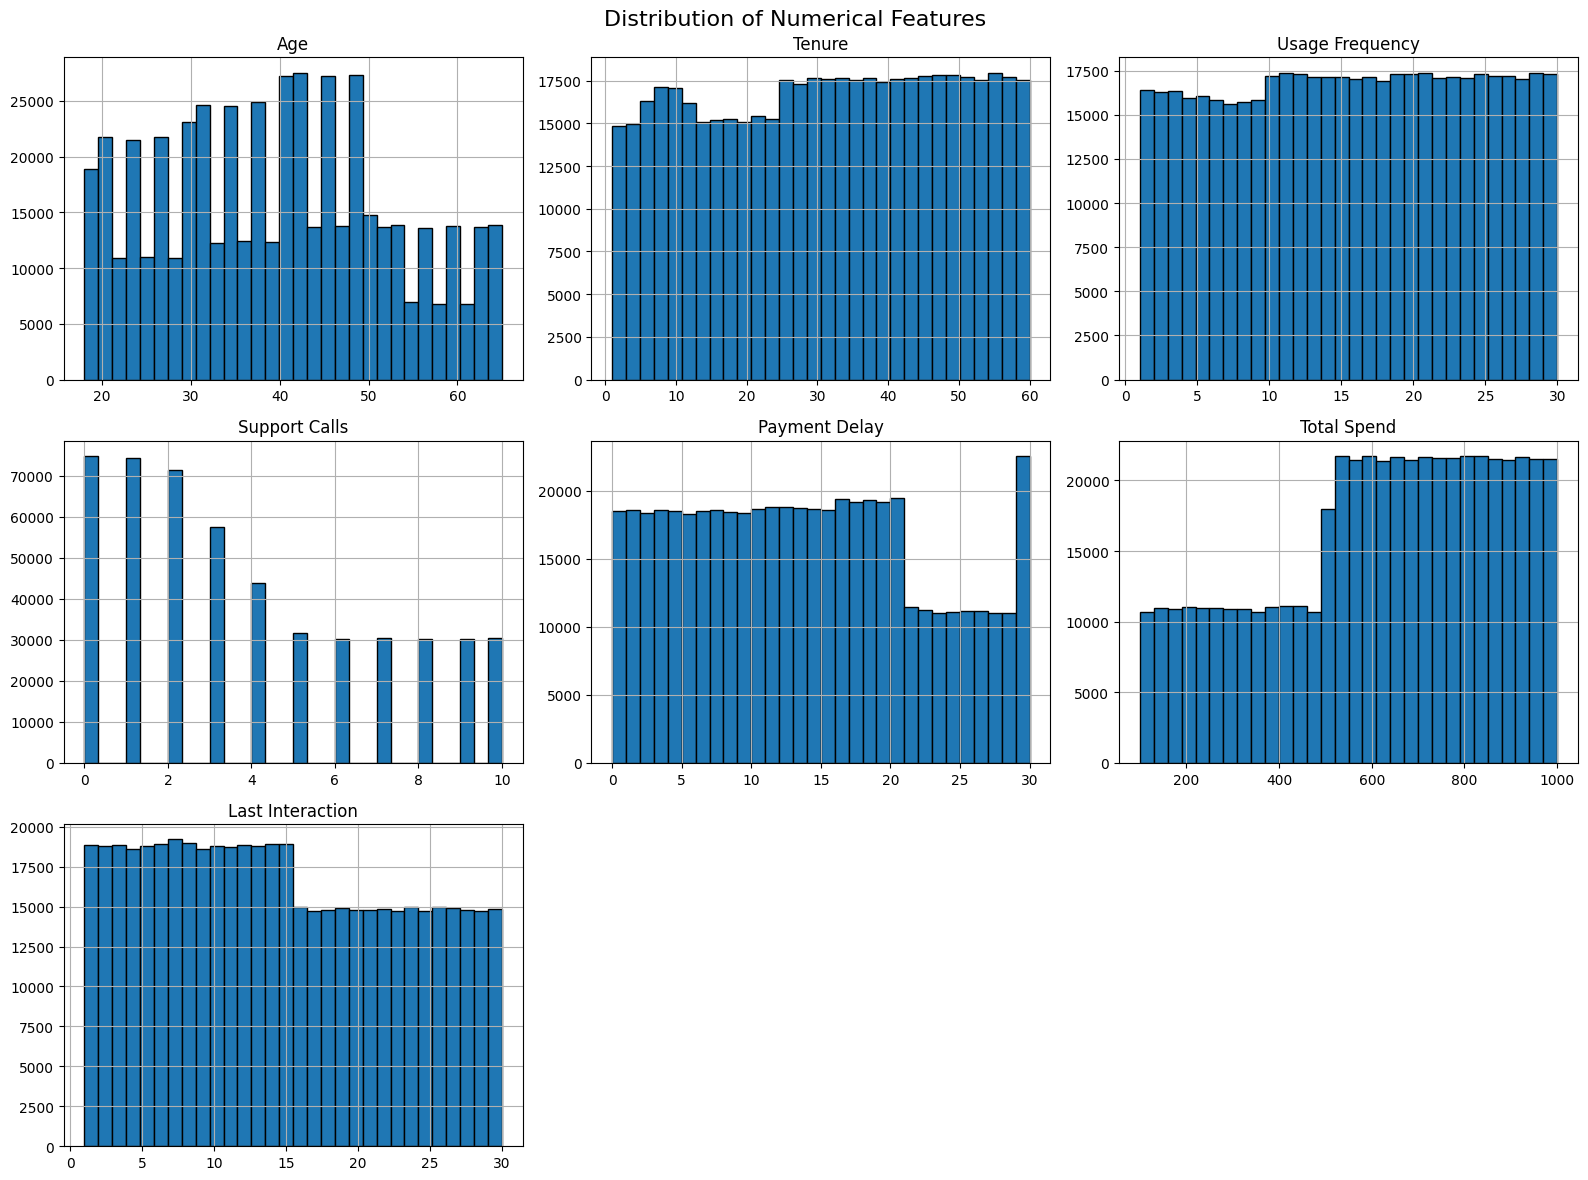

In [16]:
numerical_cols = df_customer.select_dtypes(include=['int64', 'float64']).columns.tolist()

numerical_cols.remove('Churn')


df_customer[numerical_cols].hist(figsize=(16, 12),bins=30,edgecolor='black')

plt.suptitle('Distribution of Numerical Features', fontsize=16)
plt.tight_layout()
plt.show()

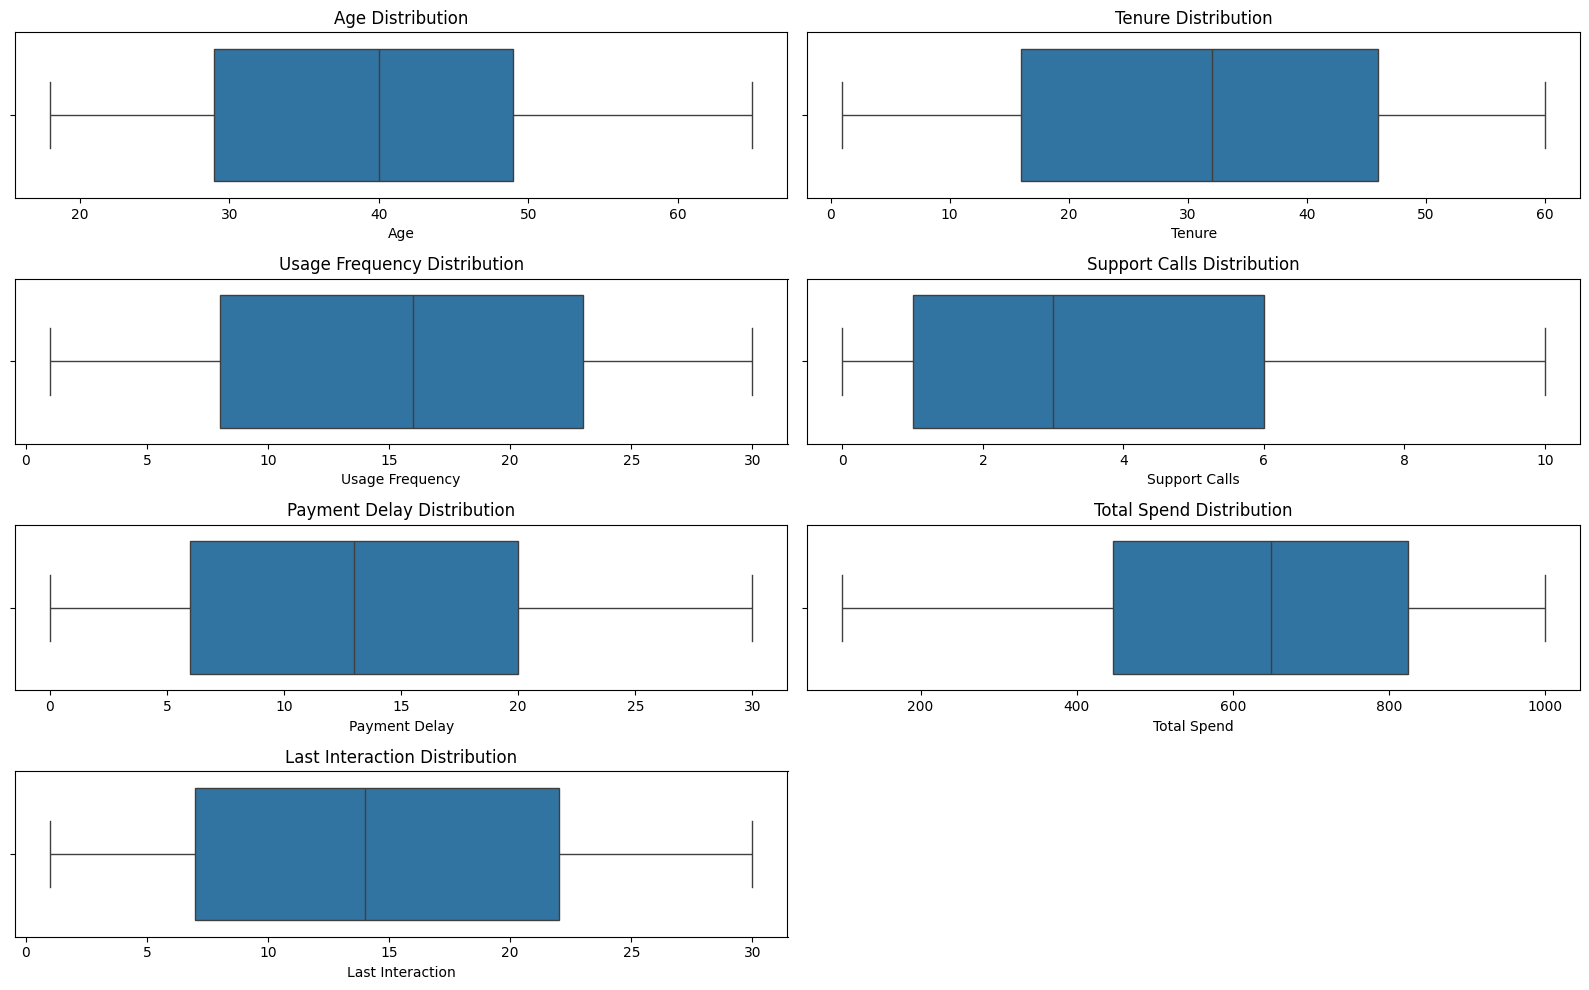

In [17]:
plt.figure(figsize=(16, 10))

for i, col in enumerate(numerical_cols, 1):
    plt.subplot(4, 2, i)

    sns.boxplot(
        x=df_customer[col]
    )

    plt.title(f'{col} Distribution')

plt.tight_layout()
plt.show()

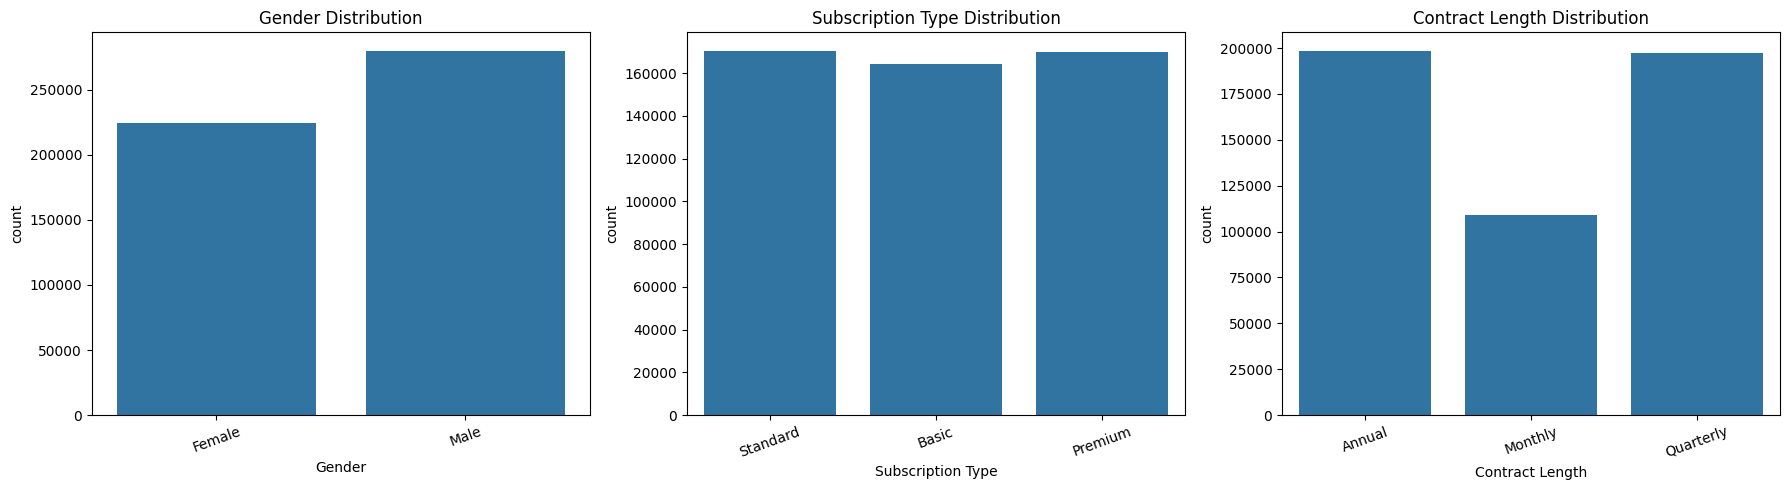

In [18]:
categorical_cols = ['Gender','Subscription Type','Contract Length']

fig, axes = plt.subplots(1,3,figsize=(18, 5))

for ax, col in zip(axes, categorical_cols):

    sns.countplot(
        data=df_customer,
        x=col,
        ax=ax
    )

    ax.set_title(f'{col} Distribution')
    ax.tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

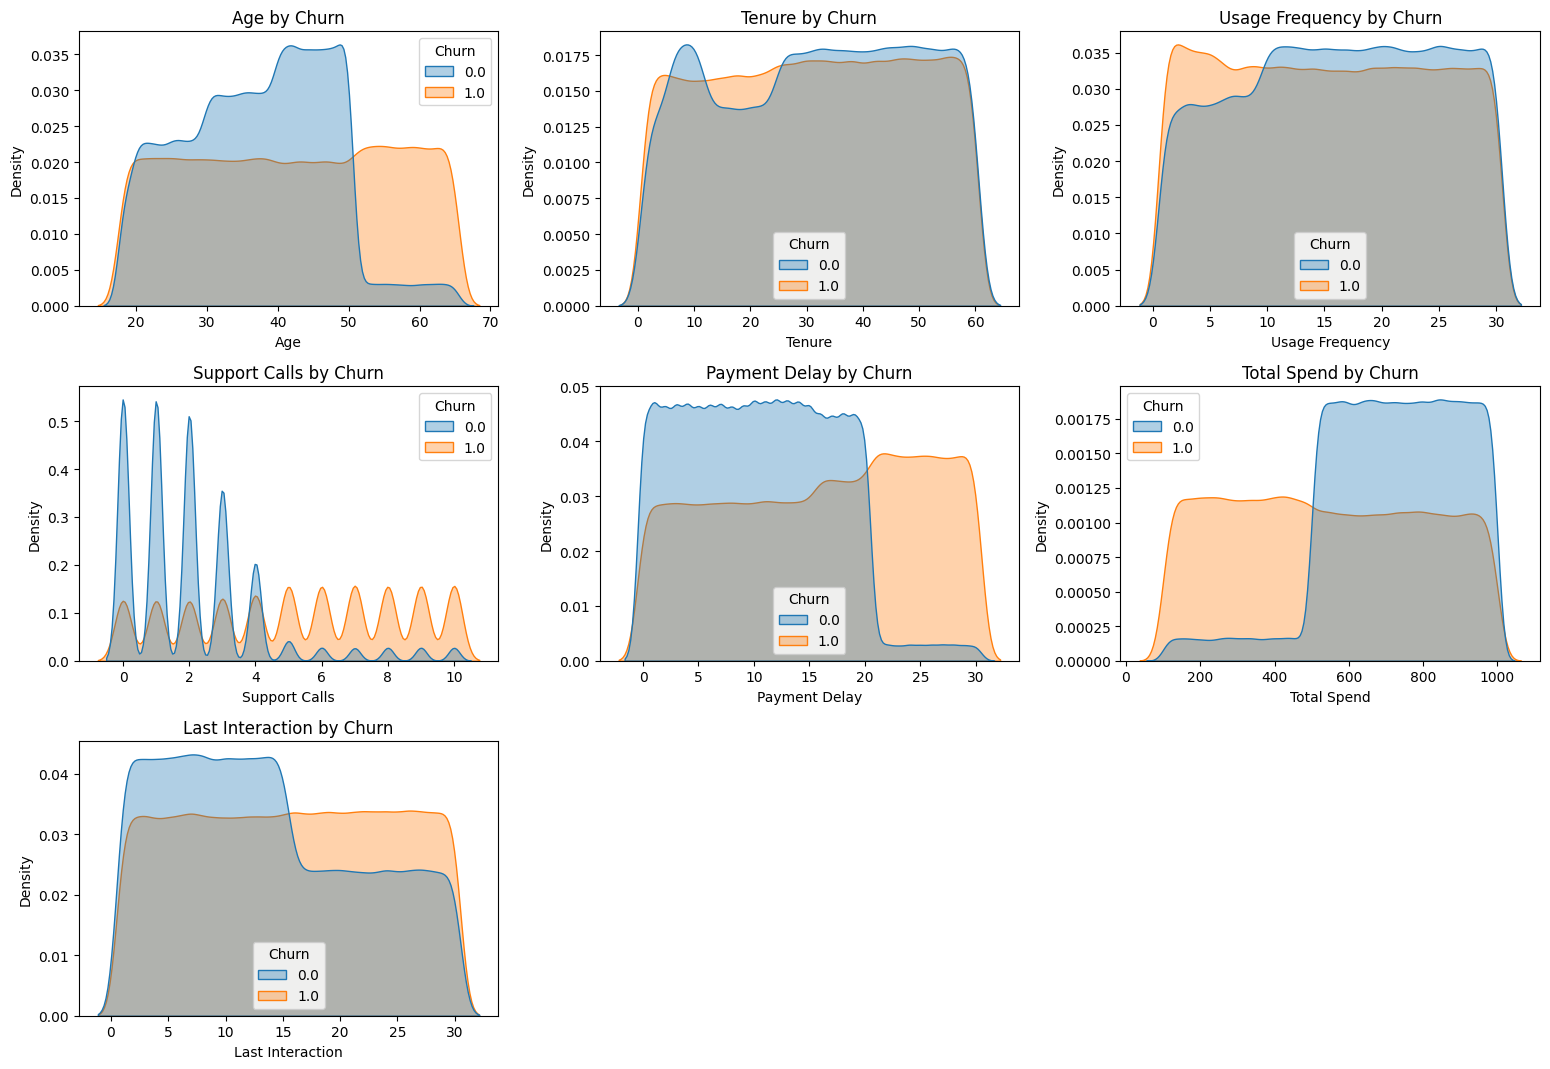

Churn,Stayed,Churned
Age,36.997201,41.872841
Tenure,31.760789,31.021683
Usage Frequency,16.227738,15.303909
Support Calls,2.025824,5.281377
Payment Delay,10.383025,15.991454
Total Spend,721.394858,538.899354
Last Interaction,13.387720,15.590266


In [19]:
# Function to Create Multiple Subplots
def create_plot_grid(number_of_plots, number_of_columns=3):

    number_of_rows = int(
        np.ceil(number_of_plots / number_of_columns)
    )

    fig, axes = plt.subplots(
        number_of_rows,
        number_of_columns,
        figsize=(
            5.2 * number_of_columns,
            3.6 * number_of_rows
        )
    )

    axes = np.array(axes).flatten()

    for ax in axes[number_of_plots:]:
        ax.set_visible(False)

    return fig, axes

# Compare Numerical Features by Churn
fig, axes = create_plot_grid(len(numerical_cols))

for ax, col in zip(axes, numerical_cols):

    sns.kdeplot(
        data=df_customer,
        x=col,
        hue='Churn',
        common_norm=False,
        fill=True,
        alpha=0.35,
        ax=ax
    )

    ax.set_title(f'{col} by Churn')


plt.tight_layout()
plt.show()


# Compare Numerical Means Between Churn Groups
churn_means = df_customer.groupby('Churn')[numerical_cols].mean().T

churn_means = churn_means.rename(
    columns={
        0: 'Stayed',
        1: 'Churned'
    }
)

display(churn_means)

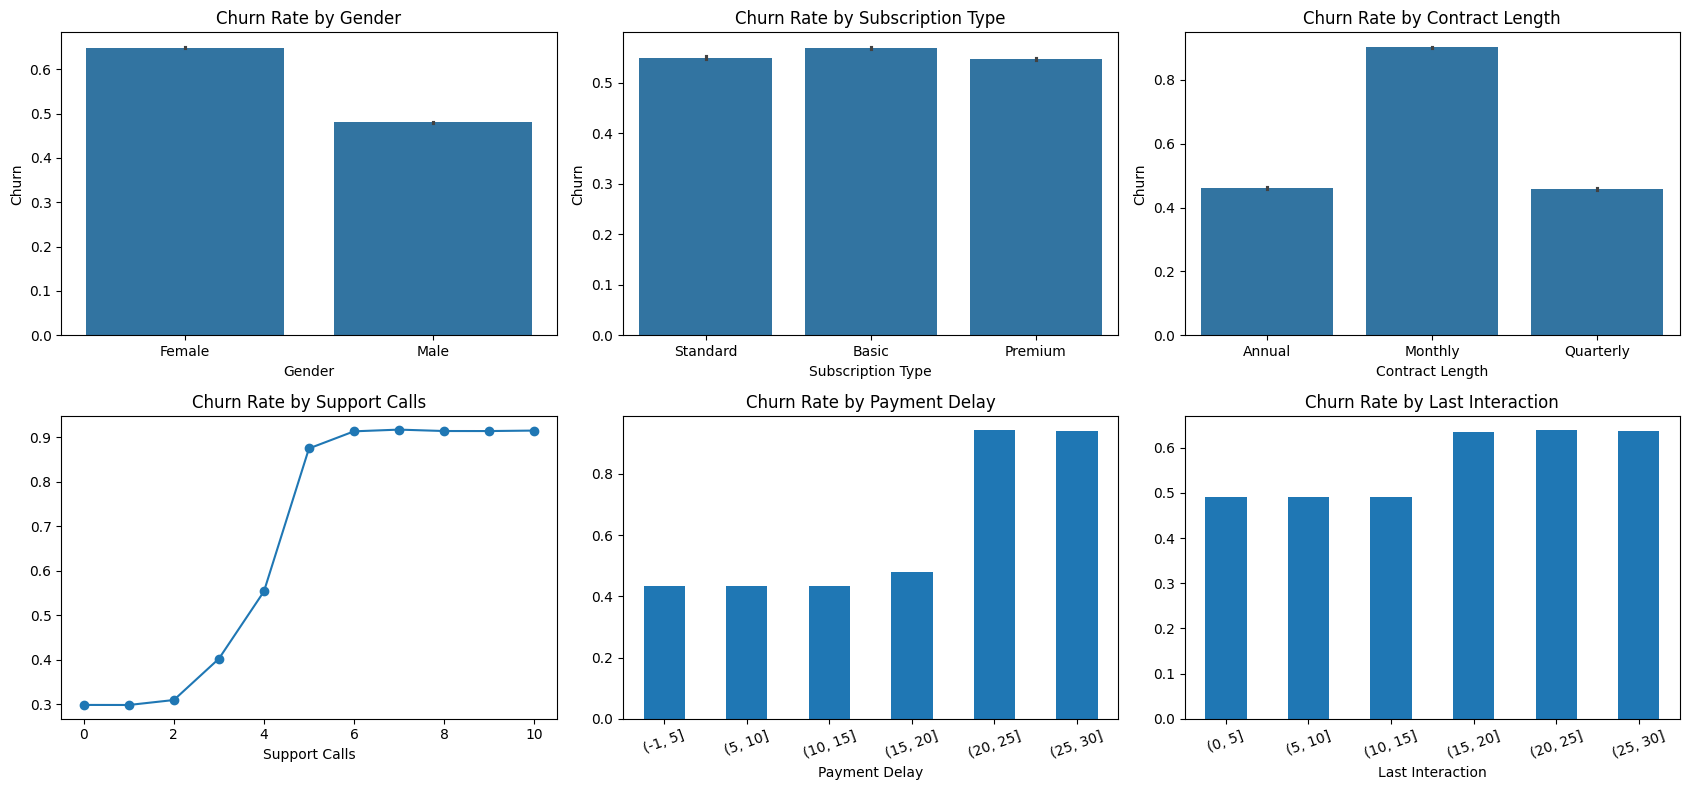

In [20]:
# Create Subplots
fig, axes = plt.subplots(
    2,
    3,
    figsize=(17, 8)
)

axes = axes.flatten()


# Categorical Features vs Churn
for ax, col in zip(axes[:3], categorical_cols):

    sns.barplot(
        data=df_customer,
        x=col,
        y='Churn',
        ax=ax
    )

    ax.set_title(f'Churn Rate by {col}')


# Support Calls vs Churn
df_customer.groupby('Support Calls')['Churn'].mean().plot(
    marker='o',
    ax=axes[3]
)

axes[3].set_title('Churn Rate by Support Calls')


# Payment Delay Groups
payment_delay_groups = pd.cut(
    df_customer['Payment Delay'],
    [-1, 5, 10, 15, 20, 25, 30]
)

df_customer.groupby(
    payment_delay_groups,
    observed=True
)['Churn'].mean().plot(
    kind='bar',
    ax=axes[4],
    rot=20
)

axes[4].set_title('Churn Rate by Payment Delay')


# Last Interaction Groups
interaction_groups = pd.cut(
    df_customer['Last Interaction'],
    [0, 5, 10, 15, 20, 25, 30]
)

df_customer.groupby(
    interaction_groups,
    observed=True
)['Churn'].mean().plot(
    kind='bar',
    ax=axes[5],
    rot=20
)

axes[5].set_title('Churn Rate by Last Interaction')


plt.tight_layout()
plt.show()

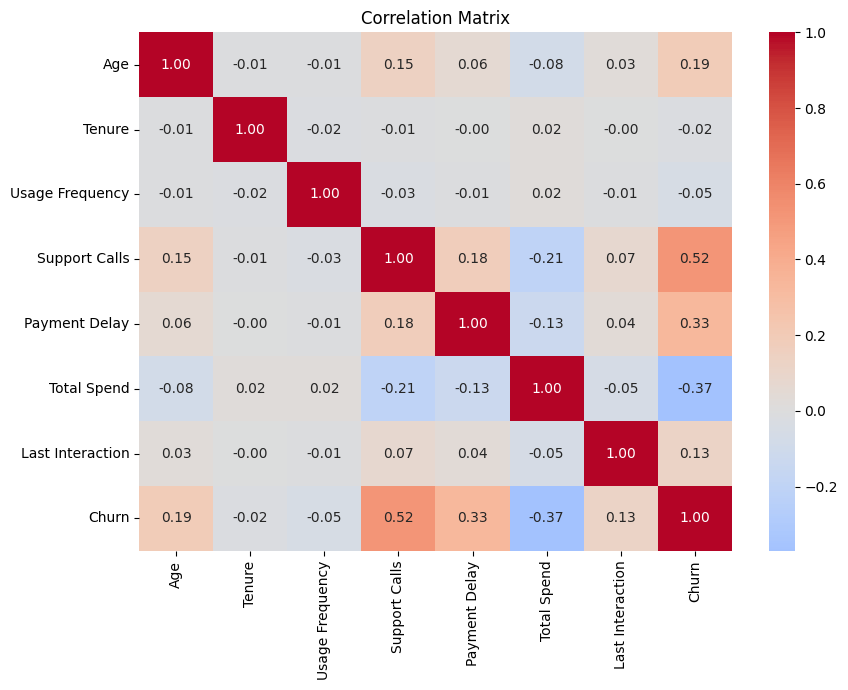

Correlation with Churn:
Support Calls       0.516
Payment Delay       0.330
Age                 0.191
Last Interaction    0.127
Tenure             -0.021
Usage Frequency    -0.053
Total Spend        -0.370
Name: Churn, dtype: float64


In [21]:
# Calculate Correlation Matrix
correlation_matrix = df_customer[
    numerical_cols + ['Churn']
].corr()


# Visualize Correlations
plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()


# Check Correlation with Churn
churn_correlation = (
    correlation_matrix['Churn']
    .drop('Churn')
    .sort_values(ascending=False)
)

print("Correlation with Churn:")
print(churn_correlation.round(3))

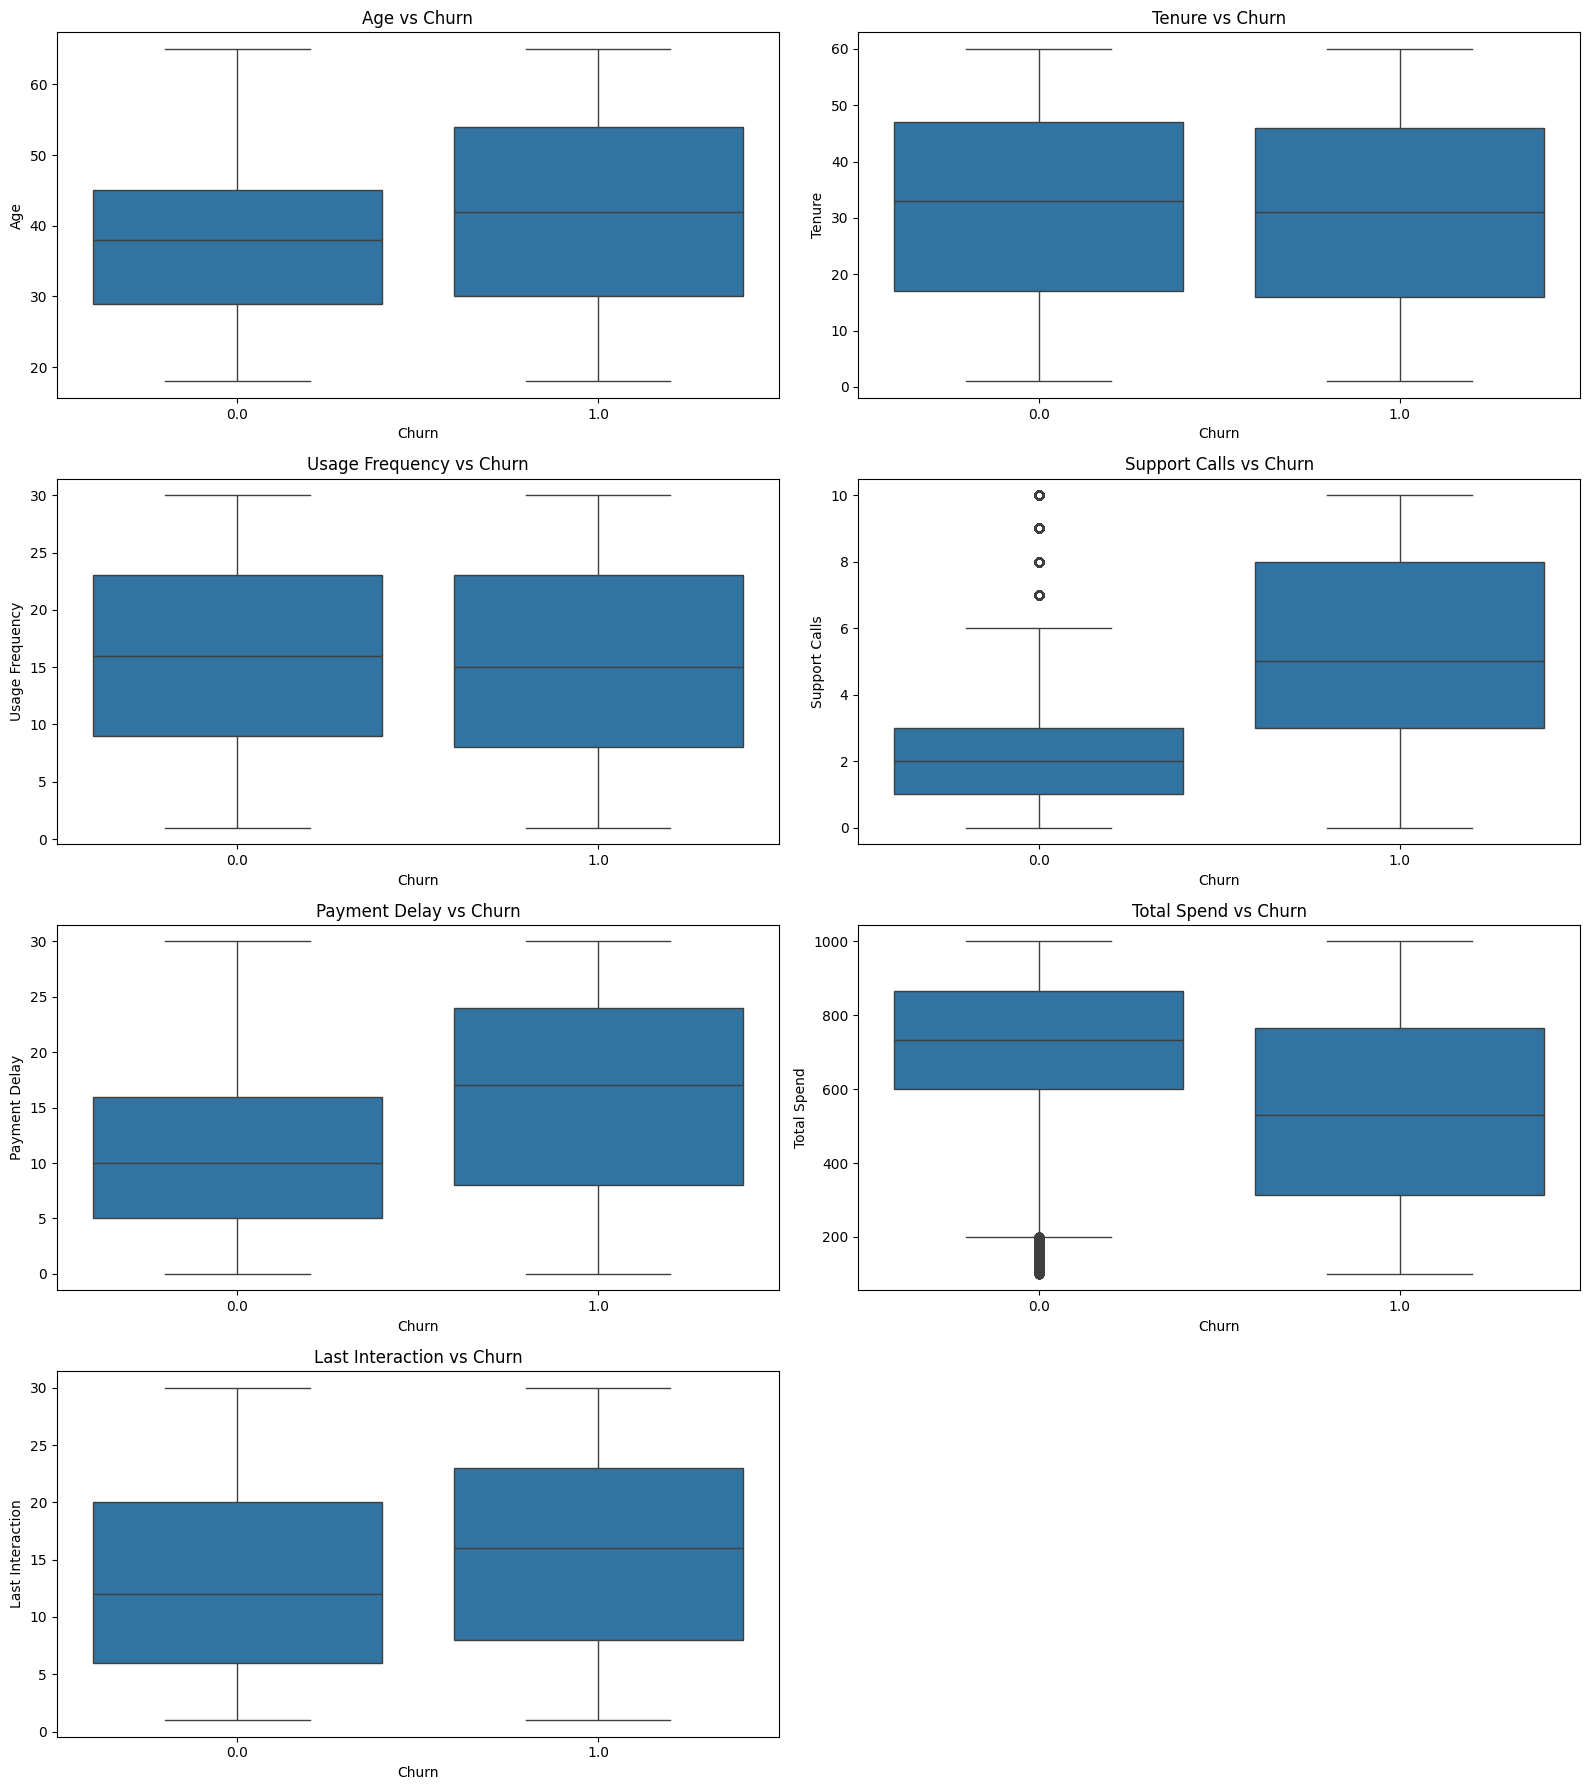

In [22]:
fig, axes = plt.subplots(4, 2, figsize=(16, 18))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):

    sns.boxplot(
        data=df_customer,
        x='Churn',
        y=col,
        ax=axes[i]
    )

    axes[i].set_title(f'{col} vs Churn')

for j in range(len(numerical_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# Feature Engineering

In [23]:
df_customer['Spend_Per_Tenure'] = (df_customer['Total Spend'] / df_customer['Tenure'])

df_customer['Support_Calls_Per_Usage'] = (df_customer['Support Calls'] / df_customer['Usage Frequency'])

df_customer[['Spend_Per_Tenure','Support_Calls_Per_Usage']].describe()

,Spend_Per_Tenure,Support_Calls_Per_Usage
count,505206.000000,505206.000000
mean,45.006412,0.512289
std,91.872842,1.044119
min,1.666667,0.000000
25%,12.662844,0.071429
50%,19.628571,0.214286
75%,37.153822,0.500000
max,1000.000000,10.000000


In [24]:
new_features = [
    'Spend_Per_Tenure',
    'Support_Calls_Per_Usage'
]

df_customer.groupby('Churn')[new_features].median().T

Churn,0.0,1.0
Spend_Per_Tenure,22.178365,17.357143
Support_Calls_Per_Usage,0.103448,0.344828


# Define Features and Target

In [25]:
X = df_customer.drop(columns=['Churn'])
y = df_customer['Churn'].astype(int)


print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (505206, 12)
Target Shape: (505206,)


In [26]:
numerical_cols = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_cols = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Numerical Features:", numerical_cols)
print("\nCategorical Features:", categorical_cols)

Numerical Features: ['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Total Spend', 'Last Interaction', 'Spend_Per_Tenure', 'Support_Calls_Per_Usage']

Categorical Features: ['Gender', 'Subscription Type', 'Contract Length']


# Train / Validation / Test Split

In [27]:
X_train_val, X_test, y_train_val, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

X_train, X_val, y_train, y_val = train_test_split(X_train_val,y_train_val,test_size=0.2,random_state=42,stratify=y_train_val)

print("Training Shape:", X_train.shape)
print("Validation Shape:", X_val.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (323331, 12)
Validation Shape: (80833, 12)
Testing Shape: (101042, 12)


# Preprocessing Pipeline

In [28]:
numerical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(
            handle_unknown='ignore',
            sparse_output=False
        ))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

# Baseline Model Training

In [29]:
lr_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(max_iter=1000))
    ]
)

In [30]:
lr_model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully.")

Logistic Regression Model Trained Successfully.


In [31]:
y_pred_lr = lr_model.predict(X_val)
y_prob_lr = lr_model.predict_proba(X_val)[:, 1]

In [32]:
logistic_results = {
    'Accuracy': accuracy_score(y_val, y_pred_lr),
    'Precision': precision_score(y_val, y_pred_lr),
    'Recall': recall_score(y_val, y_pred_lr),
    'F1 Score': f1_score(y_val, y_pred_lr),
    'ROC AUC': roc_auc_score(y_val, y_prob_lr)
}

display(pd.DataFrame(logistic_results, index=['Logistic Regression']).T)

,Logistic Regression
Accuracy,0.849925
Precision,0.874297
Recall,0.852225
F1 Score,0.863120
ROC AUC,0.909359


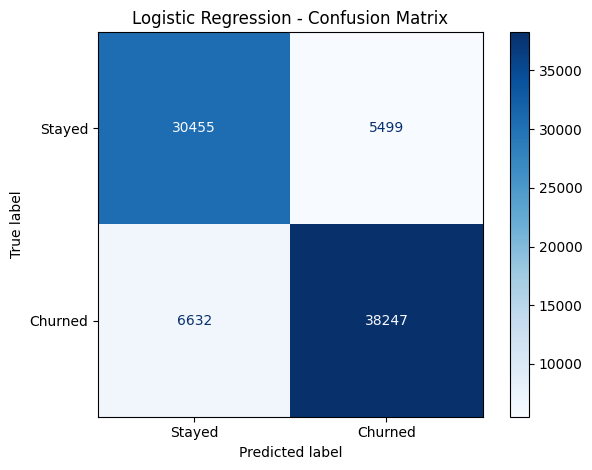

In [33]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_lr,
    display_labels=['Stayed', 'Churned'],
    cmap='Blues',
    values_format='d'
)

plt.title('Logistic Regression - Confusion Matrix')
plt.tight_layout()
plt.show()

In [34]:
dt_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', DecisionTreeClassifier(random_state=42))
    ]
)

In [35]:
dt_model.fit(X_train, y_train)

print("Decision Tree Model Trained Successfully.")

Decision Tree Model Trained Successfully.


In [36]:
y_pred_dt = dt_model.predict(X_val)

y_prob_dt = dt_model.predict_proba(X_val)[:, 1]

In [37]:
dt_results = {
    'Accuracy': accuracy_score(y_val, y_pred_dt),
    'Precision': precision_score(y_val, y_pred_dt),
    'Recall': recall_score(y_val, y_pred_dt),
    'F1 Score': f1_score(y_val, y_pred_dt),
    'ROC AUC': roc_auc_score(y_val, y_prob_dt)
}

display(pd.DataFrame(dt_results, index=['Decision Tree']).T)

,Decision Tree
Accuracy,0.884206
Precision,0.904185
Recall,0.885247
F1 Score,0.894616
ROC AUC,0.884076


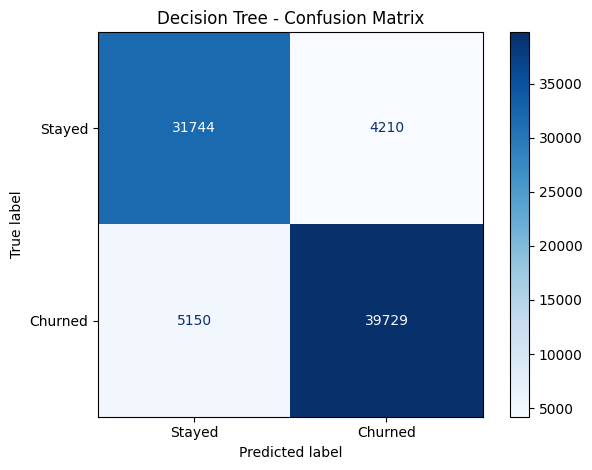

In [38]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_dt,
    display_labels=['Stayed', 'Churned'],
    cmap='Blues',
    values_format='d'
)

plt.title('Decision Tree - Confusion Matrix')
plt.tight_layout()
plt.show()

In [39]:
comparison_results = {
        'Logistic Regression': {
        'Accuracy': accuracy_score(y_val, y_pred_lr),
        'Precision': precision_score(y_val, y_pred_lr),
        'Recall': recall_score(y_val, y_pred_lr),
        'F1 Score': f1_score(y_val, y_pred_lr),
        'ROC AUC': roc_auc_score(y_val, y_prob_lr)
    },

    'Decision Tree': {
        'Accuracy': accuracy_score(y_val, y_pred_dt),
        'Precision': precision_score(y_val, y_pred_dt),
        'Recall': recall_score(y_val, y_pred_dt),
        'F1 Score': f1_score(y_val, y_pred_dt),
        'ROC AUC': roc_auc_score(y_val, y_prob_dt)
    }
}

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df)

,Logistic Regression,Decision Tree
Accuracy,0.849925,0.884206
Precision,0.874297,0.904185
Recall,0.852225,0.885247
F1 Score,0.863120,0.894616
ROC AUC,0.909359,0.884076


In [40]:
rf_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

In [41]:
rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully.")

Random Forest Model Trained Successfully.


In [42]:
y_pred_rf = rf_model.predict(X_val)

y_prob_rf = rf_model.predict_proba(X_val)[:, 1]

In [43]:
rf_results = {
    'Accuracy': accuracy_score(y_val, y_pred_rf),
    'Precision': precision_score(y_val, y_pred_rf),
    'Recall': recall_score(y_val, y_pred_rf),
    'F1 Score': f1_score(y_val, y_pred_rf),
    'ROC AUC': roc_auc_score(y_val, y_prob_rf)
}

display(pd.DataFrame(rf_results, index=['Random Forest']).T)

,Random Forest
Accuracy,0.934989
Precision,0.897273
Recall,0.997059
F1 Score,0.944538
ROC AUC,0.953454


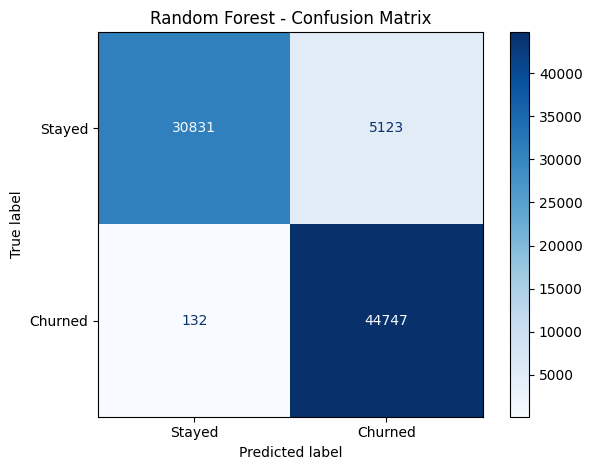

In [44]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_rf,
    display_labels=['Stayed', 'Churned'],
    cmap='Blues',
    values_format='d'
)

plt.title('Random Forest - Confusion Matrix')
plt.tight_layout()
plt.show()

In [45]:
comparison_results['Random Forest'] = rf_results

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df)

,Logistic Regression,Decision Tree,Random Forest
Accuracy,0.849925,0.884206,0.934989
Precision,0.874297,0.904185,0.897273
Recall,0.852225,0.885247,0.997059
F1 Score,0.863120,0.894616,0.944538
ROC AUC,0.909359,0.884076,0.953454


In [46]:
gb_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', HistGradientBoostingClassifier(
            max_iter=100,
            learning_rate=0.1,
            max_leaf_nodes=31,
            random_state=42
        ))
    ]
)

In [47]:
gb_model.fit(X_train, y_train)

print("Gradient Boosting Model Trained Successfully.")

Gradient Boosting Model Trained Successfully.


In [48]:
y_pred_gb = gb_model.predict(X_val)

y_prob_gb = gb_model.predict_proba(X_val)[:, 1]

In [49]:
gb_results = {
    'Accuracy': accuracy_score(y_val, y_pred_gb),
    'Precision': precision_score(y_val, y_pred_gb),
    'Recall': recall_score(y_val, y_pred_gb),
    'F1 Score': f1_score(y_val, y_pred_gb),
    'ROC AUC': roc_auc_score(y_val, y_prob_gb)
}

display(pd.DataFrame(gb_results, index=['Gradient Boosting']).T)

,Gradient Boosting
Accuracy,0.935311
Precision,0.897104
Recall,0.997950
F1 Score,0.944844
ROC AUC,0.953490


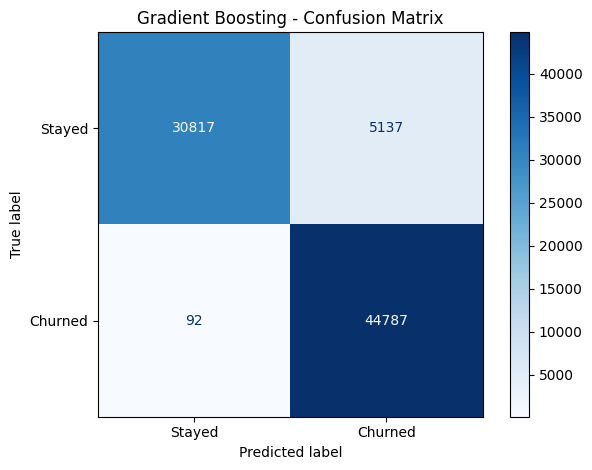

In [50]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_gb,
    display_labels=['Stayed', 'Churned'],
    cmap='Blues',
    values_format='d'
)

plt.title('Gradient Boosting - Confusion Matrix')
plt.tight_layout()
plt.show()

In [51]:
comparison_results['Gradient Boosting'] = gb_results

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df)

,Logistic Regression,Decision Tree,Random Forest,Gradient Boosting
Accuracy,0.849925,0.884206,0.934989,0.935311
Precision,0.874297,0.904185,0.897273,0.897104
Recall,0.852225,0.885247,0.997059,0.997950
F1 Score,0.863120,0.894616,0.944538,0.944844
ROC AUC,0.909359,0.884076,0.953454,0.953490


In [52]:
xgb_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', XGBClassifier(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=6,
            random_state=42,
            eval_metric='logloss',
            n_jobs=-1
        ))
    ]
)

In [53]:
xgb_model.fit(X_train, y_train)

print("XGBoost Model Trained Successfully.")

XGBoost Model Trained Successfully.


In [54]:
y_pred_xgb = xgb_model.predict(X_val)

y_prob_xgb = xgb_model.predict_proba(X_val)[:, 1]

In [55]:
xgb_results = {
    'Accuracy': accuracy_score(y_val, y_pred_xgb),
    'Precision': precision_score(y_val, y_pred_xgb),
    'Recall': recall_score(y_val, y_pred_xgb),
    'F1 Score': f1_score(y_val, y_pred_xgb),
    'ROC AUC': roc_auc_score(y_val, y_prob_xgb)
}

display(pd.DataFrame(xgb_results, index=['XGBoost']).T)

,XGBoost
Accuracy,0.932255
Precision,0.896864
Recall,0.992068
F1 Score,0.942066
ROC AUC,0.954002


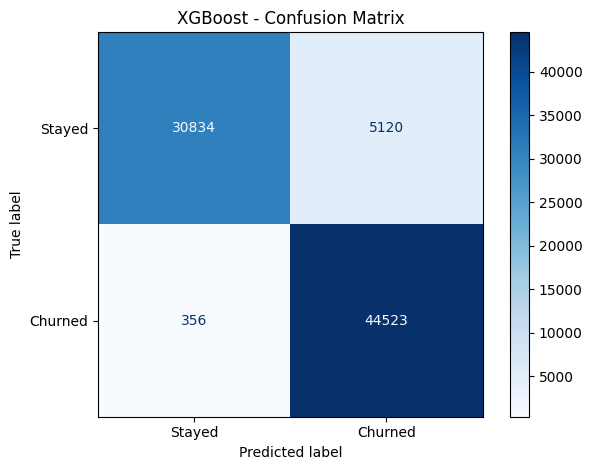

In [56]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_xgb,
    display_labels=['Stayed', 'Churned'],
    cmap='Blues',
    values_format='d'
)

plt.title('XGBoost - Confusion Matrix')
plt.tight_layout()
plt.show()

# Baseline Model Comparison

In [57]:
comparison_results['XGBoost'] = xgb_results

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df)

,Logistic Regression,Decision Tree,Random Forest,Gradient Boosting,XGBoost
Accuracy,0.849925,0.884206,0.934989,0.935311,0.932255
Precision,0.874297,0.904185,0.897273,0.897104,0.896864
Recall,0.852225,0.885247,0.997059,0.997950,0.992068
F1 Score,0.863120,0.894616,0.944538,0.944844,0.942066
ROC AUC,0.909359,0.884076,0.953454,0.953490,0.954002


# Hyperparameter Tuning & Cross Validation

In [58]:
gb_param_grid = {
    'classifier__learning_rate': [0.01, 0.03, 0.05, 0.1, 0.15],

    'classifier__max_iter': [100, 150, 200, 300],

    'classifier__max_leaf_nodes': [15, 31, 50, 63],

    'classifier__max_depth': [None, 3, 5, 7, 10],

    'classifier__min_samples_leaf': [10, 20, 30, 50],

    'classifier__l2_regularization': [0, 0.1, 1, 5, 10],

    'classifier__max_bins': [64, 128, 255]
}

In [59]:
cv_strategy = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

In [60]:
gb_random_search = RandomizedSearchCV(
    estimator=Pipeline(
        steps=[
            ('preprocessor', preprocessor),
            ('classifier', HistGradientBoostingClassifier(
                random_state=42
            ))
        ]
    ),
    param_distributions=gb_param_grid,
    n_iter=20,
    scoring='f1',
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    return_train_score=True
)

In [61]:
gb_random_search.fit(X_train, y_train)

print("Gradient Boosting Hyperparameter Tuning Completed!")

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Gradient Boosting Hyperparameter Tuning Completed!


In [62]:
print("Best Hyperparameters:")

for param, value in gb_random_search.best_params_.items():
    print(f"{param}: {value}")

print("\nBest Cross Validation F1 Score:")
print(gb_random_search.best_score_)

Best Hyperparameters:
classifier__min_samples_leaf: 30
classifier__max_leaf_nodes: 50
classifier__max_iter: 100
classifier__max_depth: 10
classifier__max_bins: 128
classifier__learning_rate: 0.15
classifier__l2_regularization: 0

Best Cross Validation F1 Score:
0.9451115080791007


In [63]:
best_gb_model = gb_random_search.best_estimator_

print("Best Gradient Boosting Model:")
print(best_gb_model)

Best Gradient Boosting Model:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'Tenure',
                                                   'Usage Frequency',
                                                   'Support Calls',
                                                   'Payment Delay',
                                                   'Total Spend',
                                                   'Last Interaction',
                                                   'Spend_Per_Tenure',
                                                   'S

In [64]:
y_pred_gb_tuned = best_gb_model.predict(X_val)
y_prob_gb_tuned = best_gb_model.predict_proba(X_val)[:, 1]

In [65]:
gb_tuned_results = {
    'Accuracy': accuracy_score(y_val, y_pred_gb_tuned),
    'Precision': precision_score(y_val, y_pred_gb_tuned),
    'Recall': recall_score(y_val, y_pred_gb_tuned),
    'F1 Score': f1_score(y_val, y_pred_gb_tuned),
    'ROC AUC': roc_auc_score(y_val, y_prob_gb_tuned)
}

display(pd.DataFrame(gb_tuned_results, index=['Gradient Boosting(Tuned)']).T)

,Gradient Boosting(Tuned)
Accuracy,0.935336
Precision,0.897155
Recall,0.997928
F1 Score,0.944862
ROC AUC,0.953985


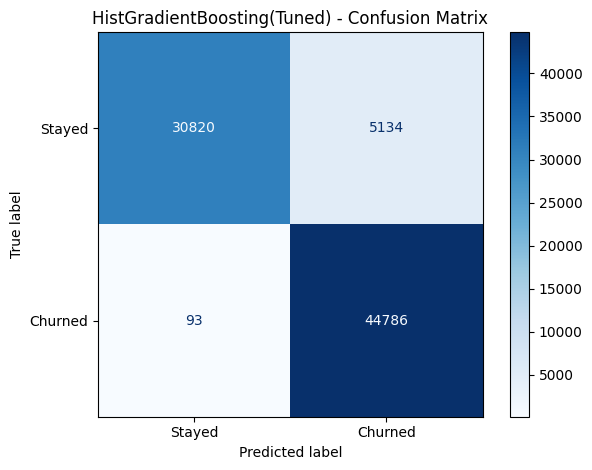

In [66]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_gb_tuned,
    display_labels=['Stayed', 'Churned'],
    cmap='Blues',
    values_format='d'
)

plt.title('HistGradientBoosting(Tuned) - Confusion Matrix')
plt.tight_layout()
plt.show()

In [67]:
comparison_results['Gradient Boosting(Tuned)'] = gb_tuned_results

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df)

,Logistic Regression,Decision Tree,Random Forest,Gradient Boosting,XGBoost,Gradient Boosting(Tuned)
Accuracy,0.849925,0.884206,0.934989,0.935311,0.932255,0.935336
Precision,0.874297,0.904185,0.897273,0.897104,0.896864,0.897155
Recall,0.852225,0.885247,0.997059,0.997950,0.992068,0.997928
F1 Score,0.863120,0.894616,0.944538,0.944844,0.942066,0.944862
ROC AUC,0.909359,0.884076,0.953454,0.953490,0.954002,0.953985


In [68]:
rf_param_grid = {
    'classifier__n_estimators': [100, 200, 300, 400, 500],

    'classifier__max_depth': [None, 10, 20, 30, 40],

    'classifier__min_samples_split': [2, 5, 10, 15],

    'classifier__min_samples_leaf': [1, 2, 4, 8],

    'classifier__max_features': ['sqrt', 'log2'],

    'classifier__class_weight': [None, 'balanced']
}

In [69]:
cv_strategy = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

In [70]:
rf_random_search = RandomizedSearchCV(
    estimator=Pipeline(
        steps=[
            ('preprocessor', preprocessor),
            ('classifier', RandomForestClassifier(
                random_state=42,
                n_jobs=1
            ))
        ]
    ),
    param_distributions=rf_param_grid,
    n_iter=15,
    scoring='recall',
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    return_train_score=True
)

In [71]:
rf_random_search.fit(X_train, y_train)

print("Random Forest Hyperparameter Tuning Completed!")

Fitting 3 folds for each of 15 candidates, totalling 45 fits
[CV] END classifier__l2_regularization=10, classifier__learning_rate=0.15, classifier__max_bins=128, classifier__max_depth=10, classifier__max_iter=200, classifier__max_leaf_nodes=31, classifier__min_samples_leaf=30; total time=   7.3s
[CV] END classifier__l2_regularization=5, classifier__learning_rate=0.03, classifier__max_bins=128, classifier__max_depth=3, classifier__max_iter=300, classifier__max_leaf_nodes=15, classifier__min_samples_leaf=50; total time=  16.6s
[CV] END classifier__l2_regularization=0.1, classifier__learning_rate=0.01, classifier__max_bins=128, classifier__max_depth=10, classifier__max_iter=100, classifier__max_leaf_nodes=63, classifier__min_samples_leaf=30; total time=  10.2s
[CV] END classifier__l2_regularization=10, classifier__learning_rate=0.05, classifier__max_bins=128, classifier__max_depth=5, classifier__max_iter=100, classifier__max_leaf_nodes=31, classifier__min_samples_leaf=50; total time=   8.

/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


[CV] END classifier__l2_regularization=5, classifier__learning_rate=0.03, classifier__max_bins=128, classifier__max_depth=3, classifier__max_iter=300, classifier__max_leaf_nodes=15, classifier__min_samples_leaf=50; total time=  17.3s
[CV] END classifier__l2_regularization=0, classifier__learning_rate=0.01, classifier__max_bins=255, classifier__max_depth=7, classifier__max_iter=150, classifier__max_leaf_nodes=63, classifier__min_samples_leaf=10; total time=  13.0s
[CV] END classifier__l2_regularization=0.1, classifier__learning_rate=0.01, classifier__max_bins=128, classifier__max_depth=10, classifier__max_iter=100, classifier__max_leaf_nodes=63, classifier__min_samples_leaf=30; total time=   9.9s
[CV] END classifier__l2_regularization=1, classifier__learning_rate=0.05, classifier__max_bins=128, classifier__max_depth=3, classifier__max_iter=300, classifier__max_leaf_nodes=63, classifier__min_samples_leaf=10; total time=  16.5s
[CV] END classifier__l2_regularization=1, classifier__learnin

In [72]:
print("Best Hyperparameters:")

for param, value in rf_random_search.best_params_.items():
    print(f"{param}: {value}")

print("\nBest Cross Validation Recall Score:")
print(rf_random_search.best_score_)

Best Hyperparameters:
classifier__n_estimators: 300
classifier__min_samples_split: 5
classifier__min_samples_leaf: 1
classifier__max_features: log2
classifier__max_depth: None
classifier__class_weight: None

Best Cross Validation Recall Score:
0.9970642958209388


In [73]:
best_rf_model = rf_random_search.best_estimator_

print("Best Random Forest Model:")
print(best_rf_model)

Best Random Forest Model:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'Tenure',
                                                   'Usage Frequency',
                                                   'Support Calls',
                                                   'Payment Delay',
                                                   'Total Spend',
                                                   'Last Interaction',
                                                   'Spend_Per_Tenure',
                                                   'Suppo

In [74]:
y_pred_rf_tuned = best_rf_model.predict(X_val)
y_prob_rf_tuned = best_rf_model.predict_proba(X_val)[:, 1]

In [75]:
rf_tuned_results = {
    'Accuracy': accuracy_score(y_val, y_pred_rf_tuned),
    'Precision': precision_score(y_val, y_pred_rf_tuned),
    'Recall': recall_score(y_val, y_pred_rf_tuned),
    'F1 Score': f1_score(y_val, y_pred_rf_tuned),
    'ROC AUC': roc_auc_score(y_val, y_prob_rf_tuned)
}

display(pd.DataFrame(rf_tuned_results, index=['Random Forest(Tuned)']).T)

,Random Forest(Tuned)
Accuracy,0.935286
Precision,0.897259
Recall,0.997683
F1 Score,0.944810
ROC AUC,0.953921


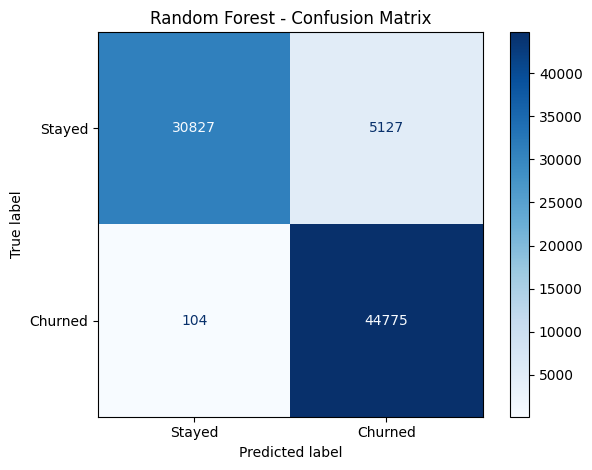

In [76]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_rf_tuned,
    display_labels=['Stayed', 'Churned'],
    cmap='Blues',
    values_format='d'
)

plt.title('Random Forest - Confusion Matrix')
plt.tight_layout()
plt.show()

In [77]:
comparison_results['Random Forest(Tuned)'] = rf_tuned_results

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df)

,Logistic Regression,Decision Tree,Random Forest,Gradient Boosting,XGBoost,Gradient Boosting(Tuned),Random Forest(Tuned)
Accuracy,0.849925,0.884206,0.934989,0.935311,0.932255,0.935336,0.935286
Precision,0.874297,0.904185,0.897273,0.897104,0.896864,0.897155,0.897259
Recall,0.852225,0.885247,0.997059,0.997950,0.992068,0.997928,0.997683
F1 Score,0.863120,0.894616,0.944538,0.944844,0.942066,0.944862,0.944810
ROC AUC,0.909359,0.884076,0.953454,0.953490,0.954002,0.953985,0.953921


In [78]:
xgb_param_grid = {
    'classifier__n_estimators': [100, 150, 200, 300, 400],

    'classifier__learning_rate': [0.01, 0.03, 0.05, 0.1, 0.15],

    'classifier__max_depth': [3, 4, 5, 6, 8],

    'classifier__min_child_weight': [1, 3, 5, 7],

    'classifier__subsample': [0.7, 0.8, 0.9, 1.0],

    'classifier__colsample_bytree': [0.7, 0.8, 0.9, 1.0],

    'classifier__gamma': [0, 0.1, 0.2, 0.5, 1],

    'classifier__reg_alpha': [0, 0.01, 0.1, 1],

    'classifier__reg_lambda': [1, 2, 5, 10]
}

In [79]:
cv_strategy = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

In [80]:
xgb_random_search = RandomizedSearchCV(
    estimator=Pipeline(
        steps=[
            ('preprocessor', preprocessor),
            ('classifier', XGBClassifier(
                random_state=42,
                eval_metric='logloss',
                n_jobs=1
            ))
        ]
    ),
    param_distributions=xgb_param_grid,
    n_iter=20,
    scoring='f1',
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    return_train_score=True
)

In [81]:
xgb_random_search.fit(X_train, y_train)

print("XGBoost Hyperparameter Tuning Completed!")

Fitting 3 folds for each of 20 candidates, totalling 60 fits
[CV] END classifier__l2_regularization=10, classifier__learning_rate=0.15, classifier__max_bins=128, classifier__max_depth=10, classifier__max_iter=200, classifier__max_leaf_nodes=31, classifier__min_samples_leaf=30; total time=   7.3s
[CV] END classifier__l2_regularization=0, classifier__learning_rate=0.01, classifier__max_bins=255, classifier__max_depth=7, classifier__max_iter=150, classifier__max_leaf_nodes=63, classifier__min_samples_leaf=10; total time=  13.2s
[CV] END classifier__l2_regularization=0, classifier__learning_rate=0.01, classifier__max_bins=255, classifier__max_depth=7, classifier__max_iter=150, classifier__max_leaf_nodes=63, classifier__min_samples_leaf=10; total time=  12.9s
[CV] END classifier__l2_regularization=10, classifier__learning_rate=0.05, classifier__max_bins=128, classifier__max_depth=5, classifier__max_iter=100, classifier__max_leaf_nodes=31, classifier__min_samples_leaf=50; total time=   8.1s


In [82]:
print("Best Hyperparameters:")

for param, value in xgb_random_search.best_params_.items():
    print(f"{param}: {value}")

print("\nBest Cross Validation F1 Score:")
print(xgb_random_search.best_score_)

Best Hyperparameters:
classifier__subsample: 0.7
classifier__reg_lambda: 2
classifier__reg_alpha: 0.01
classifier__n_estimators: 400
classifier__min_child_weight: 1
classifier__max_depth: 8
classifier__learning_rate: 0.03
classifier__gamma: 0.2
classifier__colsample_bytree: 0.8

Best Cross Validation F1 Score:
0.9436353411968644


In [83]:
best_xgb_model = xgb_random_search.best_estimator_

print("Best XGBoost Model:")
print(best_xgb_model)

Best XGBoost Model:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'Tenure',
                                                   'Usage Frequency',
                                                   'Support Calls',
                                                   'Payment Delay',
                                                   'Total Spend',
                                                   'Last Interaction',
                                                   'Spend_Per_Tenure',
                                                   'Support_Cal

In [84]:
y_pred_xgb_tuned = best_xgb_model.predict(X_val)
y_prob_xgb_tuned = best_xgb_model.predict_proba(X_val)[:, 1]

In [85]:
xgb_tuned_results = {
    'Accuracy': accuracy_score(y_val, y_pred_xgb_tuned),
    'Precision': precision_score(y_val, y_pred_xgb_tuned),
    'Recall': recall_score(y_val, y_pred_xgb_tuned),
    'F1 Score': f1_score(y_val, y_pred_xgb_tuned),
    'ROC AUC': roc_auc_score(y_val, y_prob_xgb_tuned)
}

display(pd.DataFrame(xgb_tuned_results, index=['XGBoost(Tuned)']).T)

,XGBoost(Tuned)
Accuracy,0.934024
Precision,0.897431
Recall,0.994875
F1 Score,0.943644
ROC AUC,0.954323


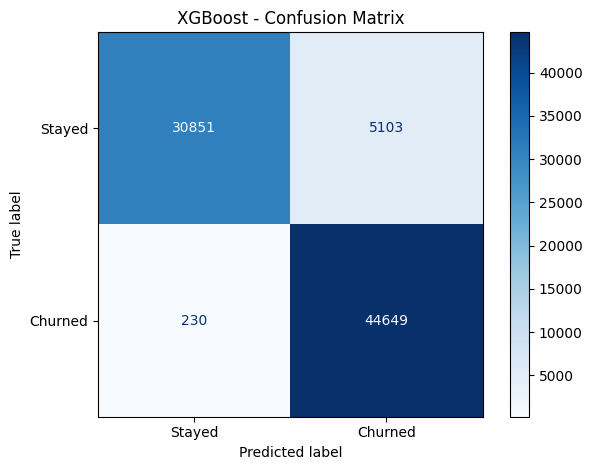

In [86]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_xgb_tuned,
    display_labels=['Stayed', 'Churned'],
    cmap='Blues',
    values_format='d'
)

plt.title('XGBoost - Confusion Matrix')
plt.tight_layout()
plt.show()

In [87]:
comparison_results['XGBoost(Tuned)'] = xgb_tuned_results

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df)

,Logistic Regression,Decision Tree,Random Forest,Gradient Boosting,XGBoost,Gradient Boosting(Tuned),Random Forest(Tuned),XGBoost(Tuned)
Accuracy,0.849925,0.884206,0.934989,0.935311,0.932255,0.935336,0.935286,0.934024
Precision,0.874297,0.904185,0.897273,0.897104,0.896864,0.897155,0.897259,0.897431
Recall,0.852225,0.885247,0.997059,0.997950,0.992068,0.997928,0.997683,0.994875
F1 Score,0.863120,0.894616,0.944538,0.944844,0.942066,0.944862,0.944810,0.943644
ROC AUC,0.909359,0.884076,0.953454,0.953490,0.954002,0.953985,0.953921,0.954323


In [88]:
# Retrieve feature names from the fitted preprocessing pipeline

preprocessor_fitted = best_gb_model.named_steps['preprocessor']

feature_names = preprocessor_fitted.get_feature_names_out()

# Remove preprocessing prefixes
feature_names = [
    name.split('__', 1)[1]
    for name in feature_names
]

print("Number of Processed Features:", len(feature_names))

print("\nFeatures used by the models:")

for i, name in enumerate(feature_names):
    print(f"{i}: {name}")

Number of Processed Features: 17

Features used by the models:
0: Age
1: Tenure
2: Usage Frequency
3: Support Calls
4: Payment Delay
5: Total Spend
6: Last Interaction
7: Spend_Per_Tenure
8: Support_Calls_Per_Usage
9: Gender_Female
10: Gender_Male
11: Subscription Type_Basic
12: Subscription Type_Premium
13: Subscription Type_Standard
14: Contract Length_Annual
15: Contract Length_Monthly
16: Contract Length_Quarterly


In [89]:
gb_val_model = best_gb_model
rf_val_model = best_rf_model
xgb_val_model = best_xgb_model

validation_models = {
    'Gradient Boosting': gb_val_model,
    'Random Forest': rf_val_model,
    'XGBoost': xgb_val_model
}

print("All Tuned Models Are Ready for Validation Analysis!")

All Tuned Models Are Ready for Validation Analysis!


# Feature Importance & SHAP

In [90]:
gb_perm_val = permutation_importance(
    gb_val_model,
    X_val,
    y_val,
    n_repeats=5,
    random_state=42,
    scoring='f1',
    n_jobs=1
)

rf_perm_val = permutation_importance(
    rf_val_model,
    X_val,
    y_val,
    n_repeats=5,
    random_state=42,
    scoring='f1',
    n_jobs=1
)

xgb_perm_val = permutation_importance(
    xgb_val_model,
    X_val,
    y_val,
    n_repeats=5,
    random_state=42,
    scoring='f1',
    n_jobs=1
)

print("Permutation Importance Completed!")

[CV] END classifier__colsample_bytree=0.7, classifier__gamma=0.5, classifier__learning_rate=0.15, classifier__max_depth=3, classifier__min_child_weight=3, classifier__n_estimators=100, classifier__reg_alpha=0.1, classifier__reg_lambda=2, classifier__subsample=0.9; total time=   4.8s
[CV] END classifier__colsample_bytree=0.7, classifier__gamma=1, classifier__learning_rate=0.01, classifier__max_depth=6, classifier__min_child_weight=1, classifier__n_estimators=150, classifier__reg_alpha=0.01, classifier__reg_lambda=10, classifier__subsample=0.7; total time=   7.4s
[CV] END classifier__colsample_bytree=0.8, classifier__gamma=0.5, classifier__learning_rate=0.01, classifier__max_depth=5, classifier__min_child_weight=3, classifier__n_estimators=400, classifier__reg_alpha=0.1, classifier__reg_lambda=5, classifier__subsample=0.9; total time=  15.6s
[CV] END classifier__colsample_bytree=0.7, classifier__gamma=0.1, classifier__learning_rate=0.1, classifier__max_depth=5, classifier__min_child_weig

In [91]:
# Get the original feature names from the validation DataFrame
original_feature_names = X_val.columns.tolist()

# Check that all arrays have the same length
print("Original Features:", len(original_feature_names))
print("Gradient Boosting:", len(gb_perm_val.importances_mean))
print("Random Forest:", len(rf_perm_val.importances_mean))
print("XGBoost:", len(xgb_perm_val.importances_mean))

# Create a DataFrame to compare feature importance across models
feature_importance_df = pd.DataFrame({
    'Feature': original_feature_names,
    'Gradient Boosting': gb_perm_val.importances_mean,
    'Random Forest': rf_perm_val.importances_mean,
    'XGBoost': xgb_perm_val.importances_mean
})

# Average importance across the three models
feature_importance_df['Average Importance'] = feature_importance_df[
    ['Gradient Boosting', 'Random Forest', 'XGBoost']
].mean(axis=1)

# Sort features by their average importance
feature_importance_df = feature_importance_df.sort_values(
    by='Average Importance',
    ascending=False
).reset_index(drop=True)

display(feature_importance_df)

Original Features: 12
Gradient Boosting: 12
Random Forest: 12
XGBoost: 12


,Feature,Gradient Boosting,Random Forest,XGBoost,Average Importance
0,Support Calls,0.135212,0.125433,0.122502,0.127715
1,Total Spend,0.088671,0.091207,0.090985,0.090288
2,Age,0.091965,0.088759,0.089113,0.089946
3,Payment Delay,0.069837,0.069747,0.069927,0.069837
4,Contract Length,0.069018,0.069063,0.069098,0.069060
5,Gender,0.046595,0.046864,0.044609,0.046023
6,Last Interaction,0.046107,0.046469,0.044251,0.045609
7,Tenure,0.017443,0.009794,0.001467,0.009568
8,Usage Frequency,0.011371,0.009009,0.004047,0.008143
9,Subscription Type,0.005152,0.004945,0.001634,0.003910


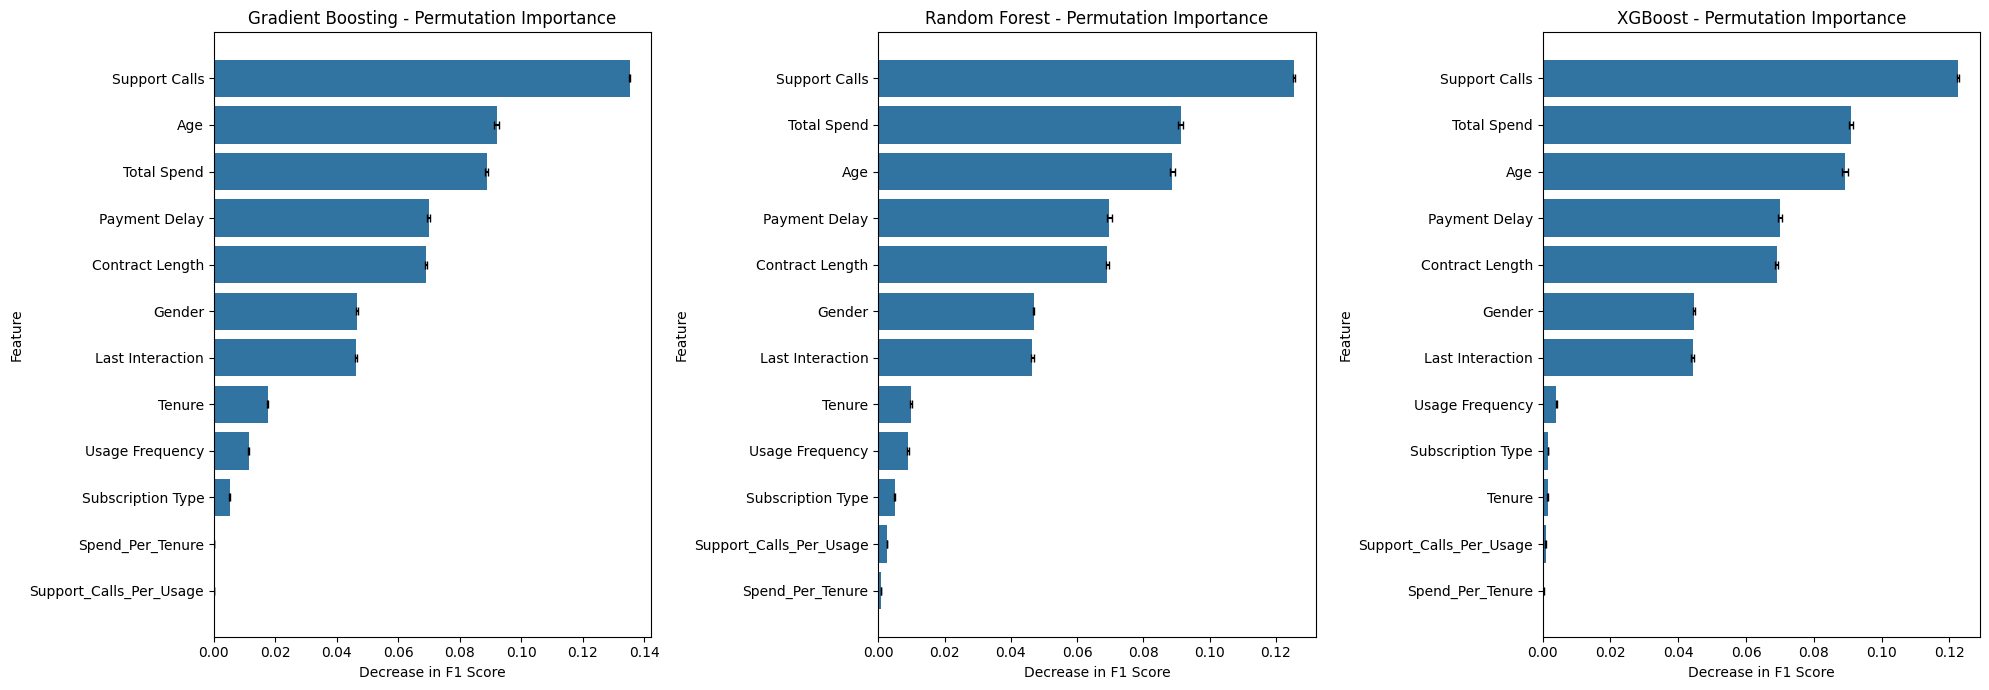

In [92]:
# Store Permutation Importance Results

perm_results = {

    'Gradient Boosting': gb_perm_val,

    'Random Forest': rf_perm_val,

    'XGBoost': xgb_perm_val

}


# Create Subplots

fig, axes = plt.subplots(1, 3, figsize=(20, 7))


for ax, (model_name, perm) in zip(axes, perm_results.items()):

    importance_df = pd.DataFrame({

        'Feature': original_feature_names,

        'Importance': perm.importances_mean,

        'Std': perm.importances_std

    }).sort_values(
        by='Importance',
        ascending=False
    ).reset_index(drop=True)


    sns.barplot(

        data=importance_df,

        x='Importance',

        y='Feature',

        ax=ax

    )


    ax.errorbar(

        importance_df['Importance'],

        range(len(importance_df)),

        xerr=importance_df['Std'],

        fmt='none',

        color='black',

        capsize=3

    )


    ax.set_title(f'{model_name} - Permutation Importance')

    ax.set_xlabel('Decrease in F1 Score')


plt.tight_layout()

plt.show()

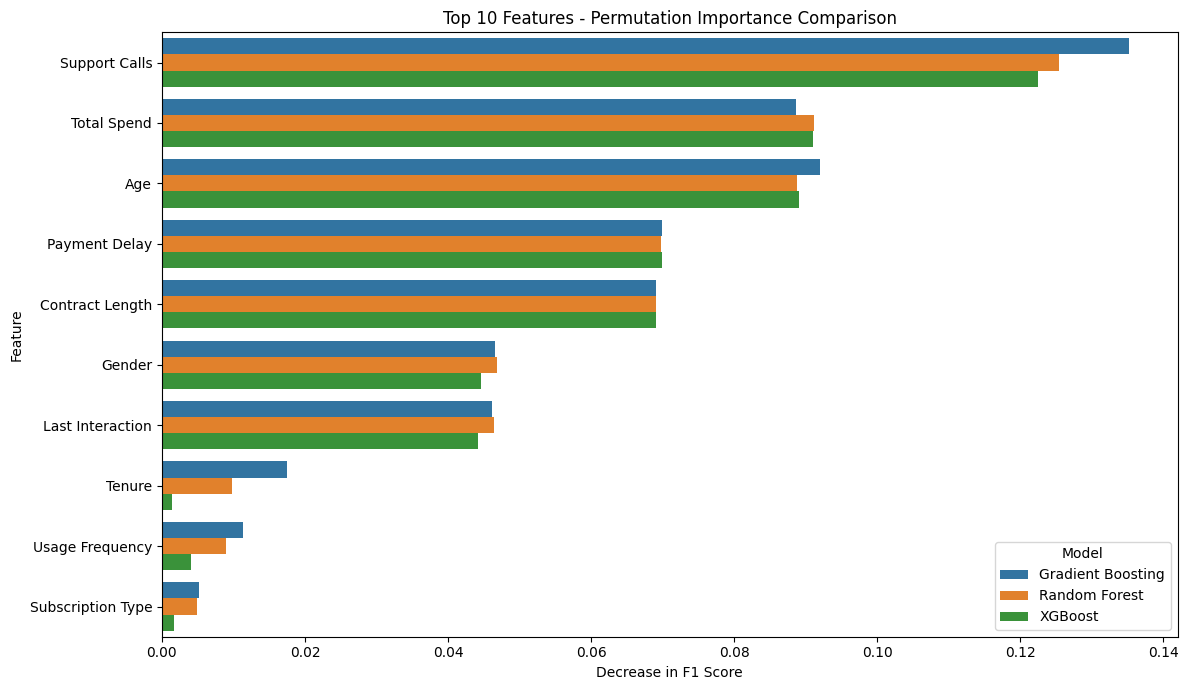

In [93]:
top_features_df = feature_importance_df.head(10)

comparison_plot_df = top_features_df.melt(
    id_vars='Feature',
    value_vars=['Gradient Boosting', 'Random Forest', 'XGBoost'],
    var_name='Model',
    value_name='Importance'
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=comparison_plot_df,
    x='Importance',
    y='Feature',
    hue='Model'
)

plt.title('Top 10 Features - Permutation Importance Comparison')
plt.xlabel('Decrease in F1 Score')
plt.tight_layout()
plt.show()

In [94]:
model_names = ['Gradient Boosting', 'Random Forest', 'XGBoost']

print("Top 3 features of each model (Permutation Importance, validation set):\n")

for model_name in model_names:
    top3 = feature_importance_df.sort_values(by=model_name, ascending=False)['Feature'].head(3).tolist()
    print(f"{model_name}: {top3}")


print("\nTop 5 features by average importance:")
display(feature_importance_df[['Feature', 'Average Importance']].head(5))


# Features that appear in the top 5 of ALL three models
top5_sets = [
    set(feature_importance_df.sort_values(by=model_name, ascending=False)['Feature'].head(5))
    for model_name in model_names
]

common_top5 = set.intersection(*top5_sets)

print("Features in the top 5 of all three models:", sorted(common_top5))


# Features that barely change the F1 Score when shuffled
low_impact_features = feature_importance_df[
    feature_importance_df['Average Importance'] < 0.001
]['Feature'].tolist()

print("Features with almost no effect (average importance < 0.001):", low_impact_features)

Top 3 features of each model (Permutation Importance, validation set):

Gradient Boosting: ['Support Calls', 'Age', 'Total Spend']
Random Forest: ['Support Calls', 'Total Spend', 'Age']
XGBoost: ['Support Calls', 'Total Spend', 'Age']

Top 5 features by average importance:


,Feature,Average Importance
0,Support Calls,0.127715
1,Total Spend,0.090288
2,Age,0.089946
3,Payment Delay,0.069837
4,Contract Length,0.069060


Features in the top 5 of all three models: ['Age', 'Contract Length', 'Payment Delay', 'Support Calls', 'Total Spend']
Features with almost no effect (average importance < 0.001): ['Spend_Per_Tenure']


In [95]:
# Random sample from the validation set to keep SHAP fast and memory-friendly
shap_sample_size = 1000
shap_sample_size_rf = 200

rng = np.random.RandomState(42)

shap_indices = rng.choice(
    X_val.shape[0],
    size=shap_sample_size,
    replace=False
)

# Select rows using iloc because X_val is a DataFrame
X_shap = X_val.iloc[shap_indices].copy()

# Keep the original feature names
shap_feature_names = X_shap.columns.tolist()

# Create a display version for SHAP plots
X_shap_display = X_shap.copy()

print("SHAP sample shape:", X_shap.shape)
print("Number of features:", len(shap_feature_names))

display(X_shap_display.head())

SHAP sample shape: (1000, 12)
Number of features: 12


,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Spend_Per_Tenure,Support_Calls_Per_Usage
370577,42.0,Male,47.0,5.0,4.0,3.0,Standard,Annual,971.15,27.0,20.662766,0.800000
189421,43.0,Male,33.0,7.0,7.0,5.0,Premium,Annual,361.00,27.0,10.939394,1.000000
381063,27.0,Female,10.0,29.0,0.0,7.0,Standard,Annual,870.30,6.0,87.030000,0.000000
81660,49.0,Female,19.0,10.0,7.0,11.0,Standard,Quarterly,605.00,9.0,31.842105,0.700000
182002,31.0,Female,35.0,11.0,9.0,25.0,Basic,Monthly,207.00,18.0,5.914286,0.818182


In [96]:
import time

shap_times = {}

start_time = time.time()

# Create temporary numerical representations for SHAP
# without changing the original training or validation data

shap_feature_names = X_shap.columns.tolist()

X_background = X_train.sample(
    n=100,
    random_state=42
).copy()

# Store category mappings
category_mappings = {}

for col in categorical_cols:

    categories = pd.Index(
        pd.concat([
            X_background[col],
            X_shap[col]
        ]).dropna().unique()
    )

    category_mappings[col] = categories


# Encode categorical columns temporarily
def encode_for_shap(data):

    encoded = data.copy()

    for col in categorical_cols:

        encoded[col] = pd.Categorical(
            encoded[col],
            categories=category_mappings[col]
        ).codes

    return encoded.astype(float)


# Decode the temporary numerical values back to original categories
def decode_from_shap(data):

    decoded = pd.DataFrame(
        data,
        columns=shap_feature_names
    )

    for col in categorical_cols:

        category_indices = np.rint(
            decoded[col]
        ).astype(int)

        decoded[col] = [
            category_mappings[col][i]
            if 0 <= i < len(category_mappings[col])
            else category_mappings[col][0]
            for i in category_indices
        ]

    return decoded


X_background_encoded = encode_for_shap(X_background)
X_shap_encoded = encode_for_shap(X_shap)


# Prediction function using the original trained pipeline
def gb_predict(data):

    decoded_data = decode_from_shap(data)

    return gb_val_model.predict_proba(decoded_data)[:, 1]


gb_explainer = shap.Explainer(
    gb_predict,
    X_background_encoded,
    algorithm='permutation',
    feature_names=shap_feature_names,
    seed=42
)


gb_shap_values = gb_explainer(
    X_shap_encoded,
    max_evals=2 * len(shap_feature_names) + 1
).values


shap_times['Gradient Boosting'] = (
    time.time() - start_time
) / len(X_shap_encoded) * 100


print("Gradient Boosting SHAP values:", gb_shap_values.shape)

PermutationExplainer explainer: 1001it [00:41, 18.13it/s]                         

Gradient Boosting SHAP values: (1000, 12)


In [97]:
start_time = time.time()

def xgb_predict(data):

    decoded_data = decode_from_shap(data)

    return xgb_val_model.predict_proba(decoded_data)[:, 1]


xgb_explainer = shap.Explainer(
    xgb_predict,
    X_background_encoded,
    algorithm='permutation',
    feature_names=shap_feature_names,
    seed=42
)

xgb_shap_values = xgb_explainer(
    X_shap_encoded,
    max_evals=2 * len(shap_feature_names) + 1
).values


shap_times['XGBoost'] = (
    time.time() - start_time
) / len(X_shap_encoded) * 100

print("XGBoost SHAP values:", xgb_shap_values.shape)

PermutationExplainer explainer: 1001it [01:07, 12.58it/s]                          

XGBoost SHAP values: (1000, 12)


In [98]:
start_time = time.time()

def rf_predict(data):

    decoded_data = decode_from_shap(data)

    return rf_val_model.predict_proba(decoded_data)[:, 1]


rf_explainer = shap.Explainer(
    rf_predict,
    X_background_encoded,
    algorithm='permutation',
    feature_names=shap_feature_names,
    seed=42
)

rf_shap_values = rf_explainer(
    X_shap_encoded,
    max_evals=2 * len(shap_feature_names) + 1
).values


shap_times['Random Forest'] = (
    time.time() - start_time
) / len(X_shap_encoded) * 100

print("Random Forest SHAP values:", rf_shap_values.shape)

PermutationExplainer explainer: 1001it [05:03,  3.18it/s]                          

Random Forest SHAP values: (1000, 12)


In [99]:
# Store SHAP values for all models
shap_results = {
    'Gradient Boosting': gb_shap_values,
    'Random Forest': rf_shap_values,
    'XGBoost': xgb_shap_values
}

# Initialize Feature Importance DataFrame
shap_importance_df = pd.DataFrame({
    'Feature': shap_feature_names
})

# Calculate Mean Absolute SHAP Values
for model_name, shap_values in shap_results.items():

    shap_importance_df[model_name] = np.abs(shap_values).mean(axis=0)

# Calculate Normalized Importance for Each Model
model_names = list(shap_results.keys())

normalized_importance = (
    shap_importance_df[model_names]
    .div(shap_importance_df[model_names].sum(axis=0), axis=1)
)

# Calculate Average Share Across Models
shap_importance_df['Average Share'] = normalized_importance.mean(axis=1)

# Sort Features by Average Importance
shap_importance_df = shap_importance_df.sort_values(
    by='Average Share',
    ascending=False
).reset_index(drop=True)

display(shap_importance_df)

,Feature,Gradient Boosting,Random Forest,XGBoost,Average Share
0,Support Calls,0.125564,0.103798,0.116207,0.201806
1,Total Spend,0.100110,0.094730,0.095337,0.169453
2,Payment Delay,0.079692,0.081545,0.084368,0.143417
3,Age,0.071463,0.063964,0.071703,0.120954
4,Contract Length,0.059021,0.057507,0.061715,0.104083
5,Gender,0.049714,0.049444,0.050312,0.087283
6,Last Interaction,0.042227,0.040111,0.042487,0.072891
7,Tenure,0.017509,0.019834,0.013827,0.029884
8,Support_Calls_Per_Usage,0.004988,0.028709,0.014121,0.027912
9,Usage Frequency,0.012770,0.012723,0.010359,0.020937


/tmp/ipykernel_50/1470295153.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


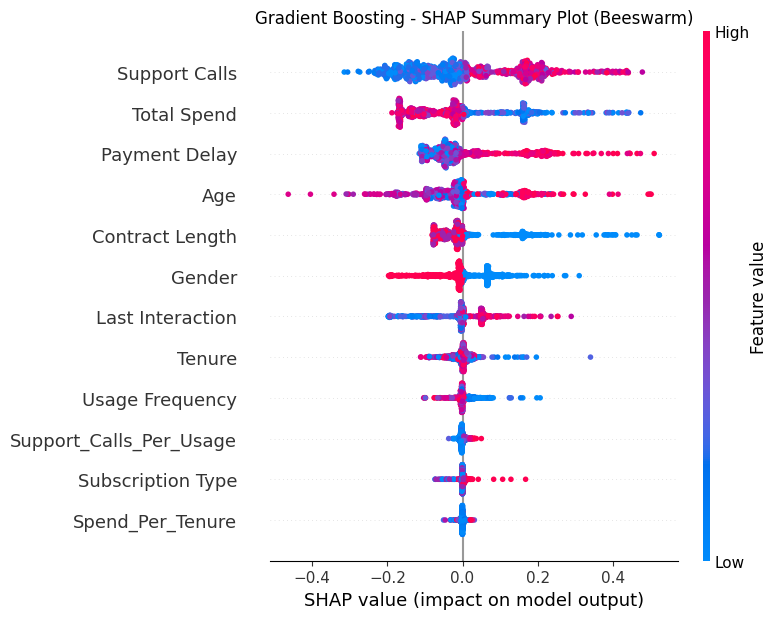

/tmp/ipykernel_50/1470295153.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


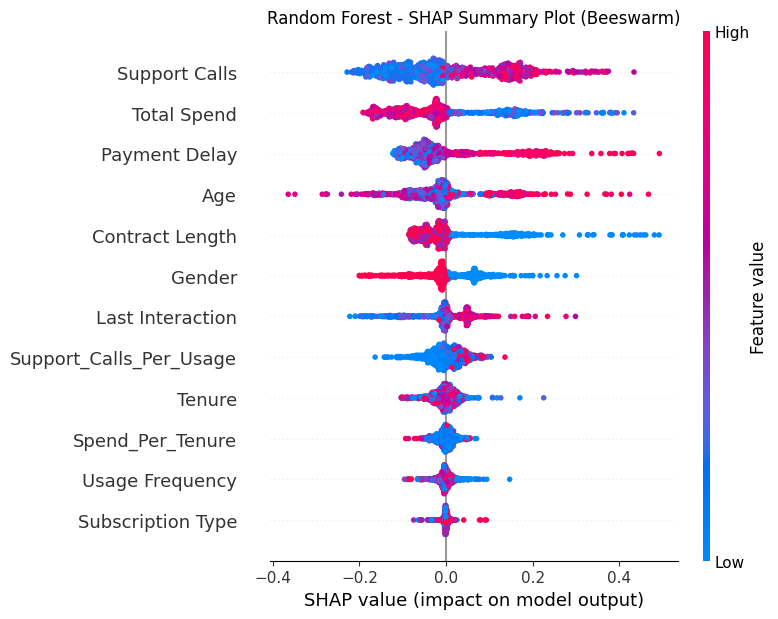

/tmp/ipykernel_50/1470295153.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


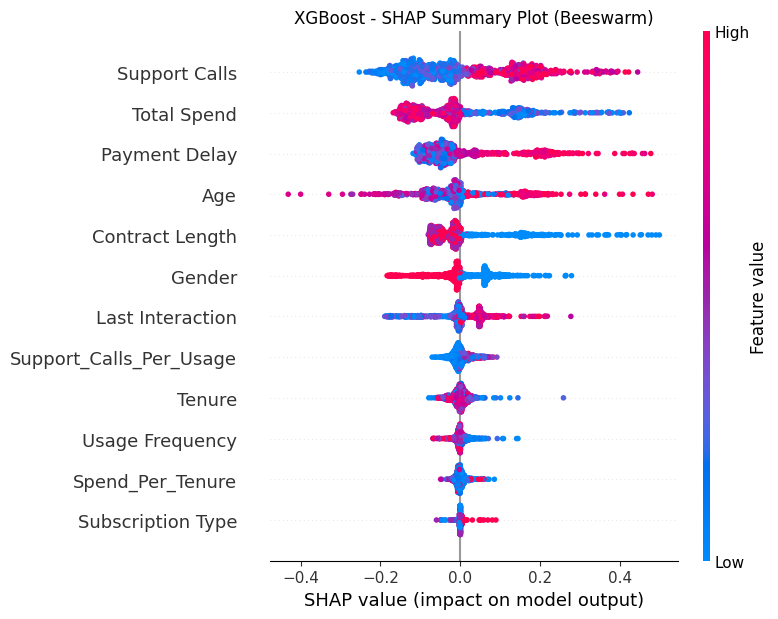

In [100]:
for model_name, shap_values in shap_results.items():

    shap.summary_plot(
        shap_values,
        X_shap_encoded,
        feature_names=shap_feature_names,
        show=False
    )

    plt.title(f'{model_name} - SHAP Summary Plot (Beeswarm)')
    plt.tight_layout()
    plt.show()

/tmp/ipykernel_50/532373788.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


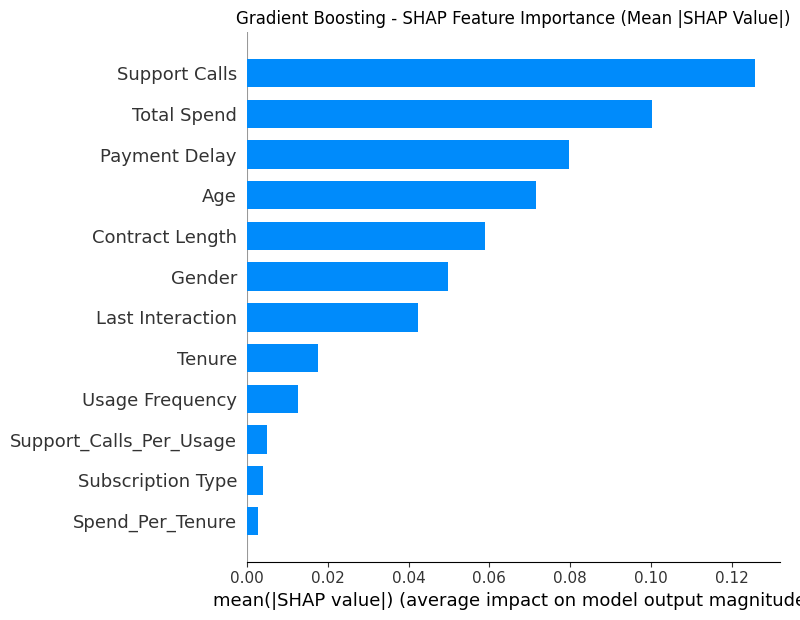

/tmp/ipykernel_50/532373788.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


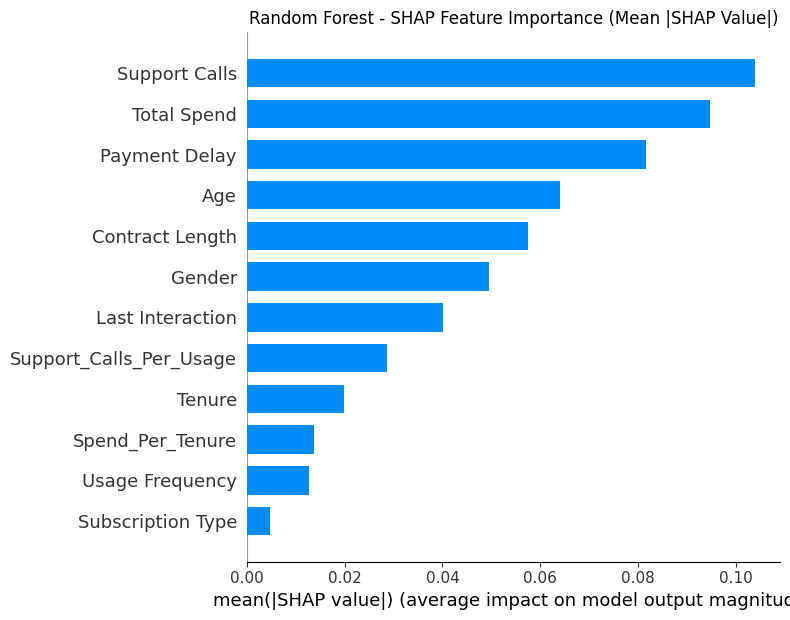

/tmp/ipykernel_50/532373788.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


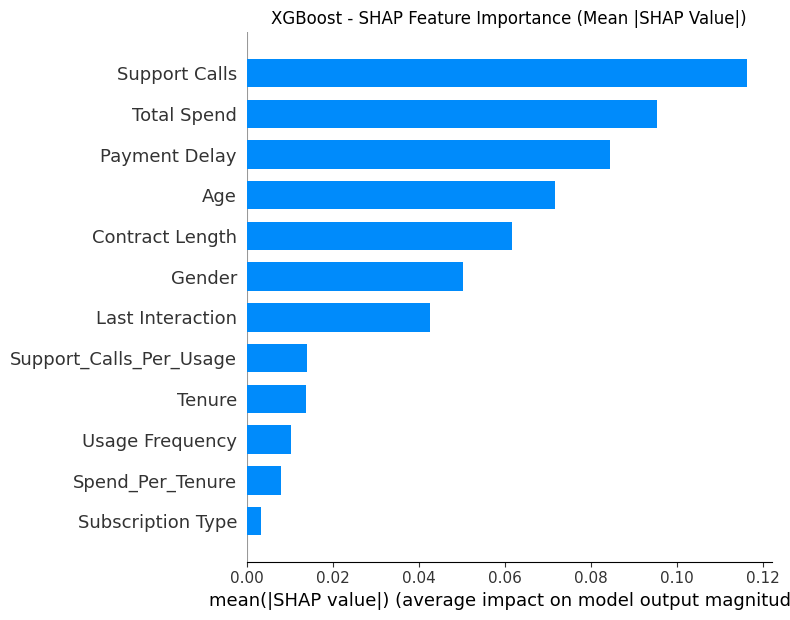

In [101]:
for model_name, shap_values in shap_results.items():

    shap.summary_plot(
        shap_values,
        X_shap_encoded,
        feature_names=shap_feature_names,
        plot_type='bar',
        show=False
    )

    plt.title(f'{model_name} - SHAP Feature Importance (Mean |SHAP Value|)')
    plt.tight_layout()
    plt.show()

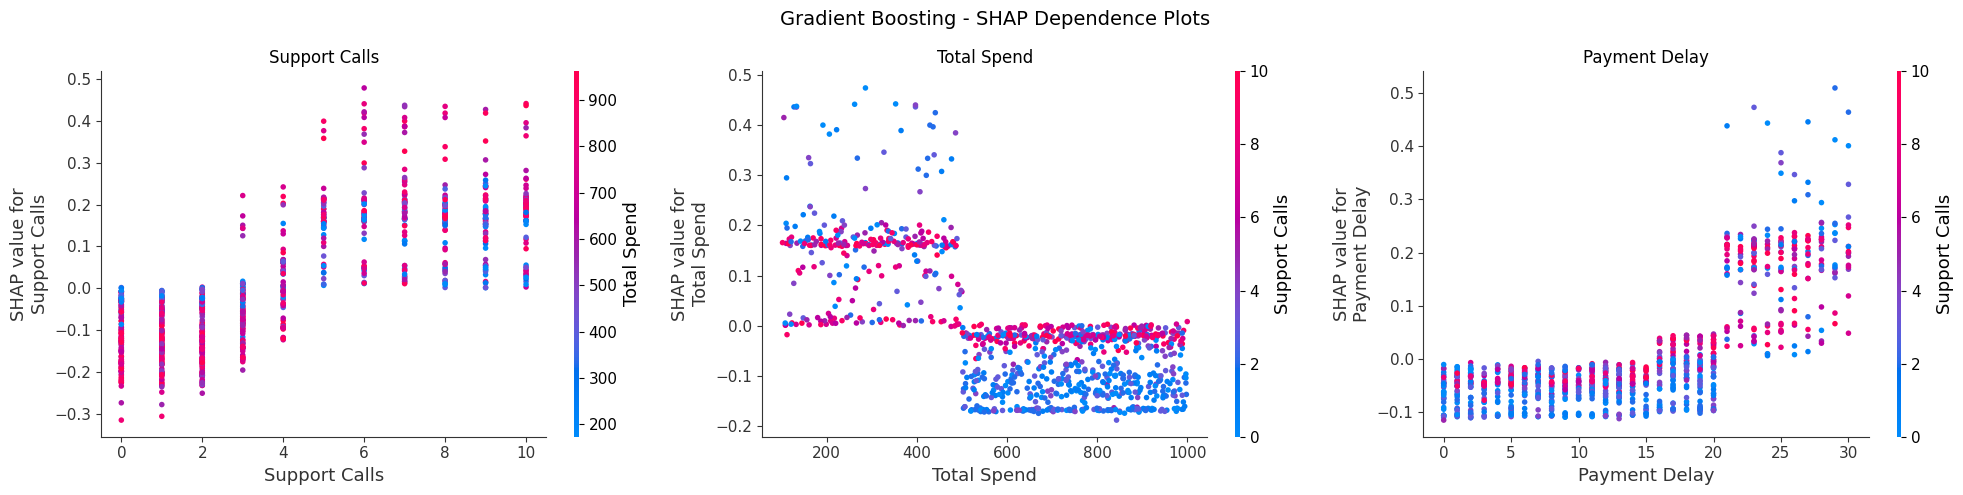

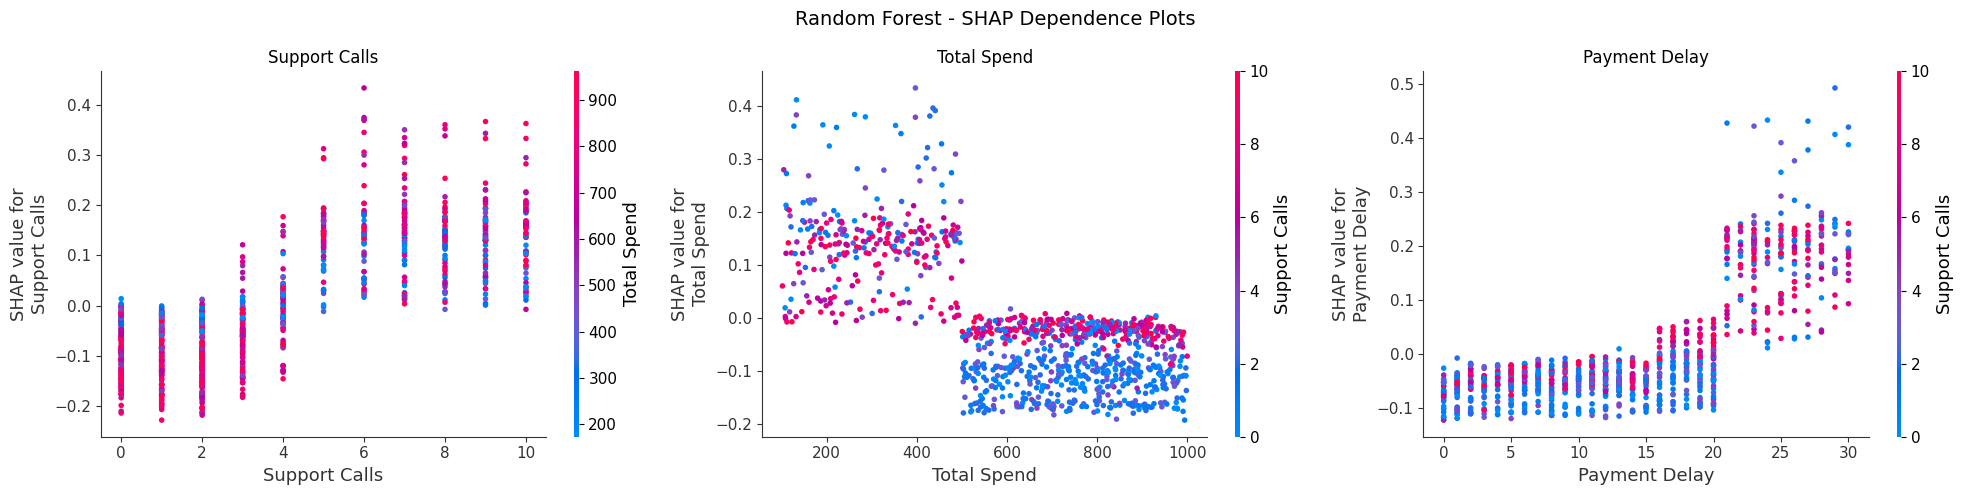

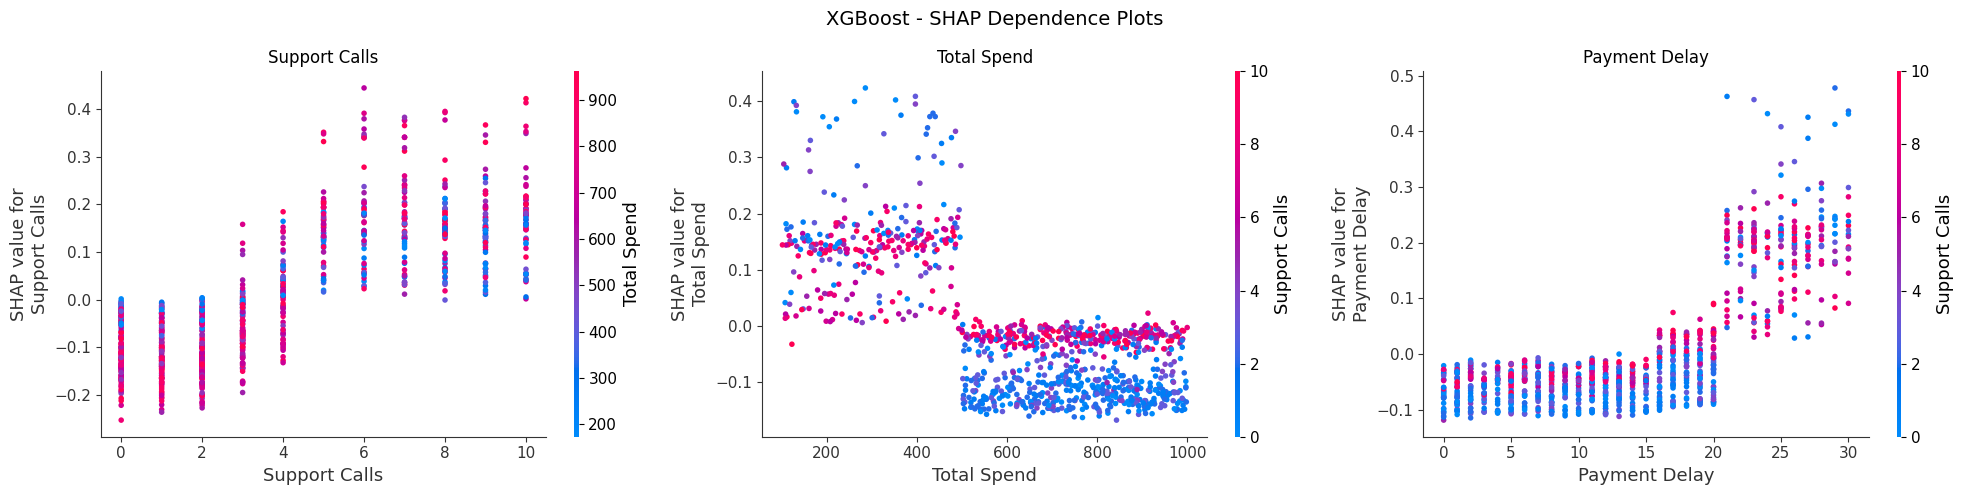

In [102]:
for model_name, shap_values in shap_results.items():

    # Get the three most important features according to SHAP
    top3_features = pd.Series(
        np.abs(shap_values).mean(axis=0),
        index=shap_feature_names
    ).sort_values(ascending=False).head(3).index.tolist()

    fig, axes = plt.subplots(1, 3, figsize=(20, 5))

    for ax, feature in zip(axes, top3_features):

        shap.dependence_plot(
            feature,
            shap_values,
            X_shap_encoded,
            feature_names=shap_feature_names,
            ax=ax,
            show=False
        )

        ax.set_title(feature)

    fig.suptitle(
        f'{model_name} - SHAP Dependence Plots',
        fontsize=14
    )

    plt.tight_layout()
    plt.show()

In [103]:
# Align Permutation and SHAP Importance Tables
perm_table = feature_importance_df.set_index('Feature').loc[shap_feature_names]
shap_table = shap_importance_df.set_index('Feature').loc[shap_feature_names]

rank_comparison_df = pd.DataFrame({
    'Feature': shap_feature_names
})

rank_correlation = {}

for model_name in model_names:

    # Calculate feature ranks
    perm_rank = perm_table[model_name].rank(ascending=False).values
    shap_rank = shap_table[model_name].rank(ascending=False).values

    rank_comparison_df[f'{model_name} - Permutation Rank'] = perm_rank
    rank_comparison_df[f'{model_name} - SHAP Rank'] = shap_rank

    # Calculate Spearman Rank Correlation
    rank_correlation[model_name] = spearmanr(
        perm_table[model_name],
        shap_table[model_name]
    )[0]


# Sort Features by Gradient Boosting SHAP Rank
rank_comparison_df = rank_comparison_df.sort_values(
    by='Gradient Boosting - SHAP Rank'
).reset_index(drop=True)

display(rank_comparison_df)


# Display Rank Correlations
print("Spearman rank correlation between Permutation Importance and SHAP:")

for model_name in model_names:
    print(f"{model_name}: {rank_correlation[model_name]:.3f}")


# Compare Top 5 Features
print("\nTop 5 features: Permutation vs SHAP")

for model_name in model_names:

    perm_top5 = set(
        perm_table[model_name]
        .sort_values(ascending=False)
        .head(5).index
    )

    shap_top5 = set(
        shap_table[model_name]
        .sort_values(ascending=False)
        .head(5).index
    )

    print(
        f"{model_name}: "
        f"{len(perm_top5 & shap_top5)} of 5 features are shared"
    )

,Feature,Gradient Boosting - Permutation Rank,Gradient Boosting - SHAP Rank,Random Forest - Permutation Rank,Random Forest - SHAP Rank,XGBoost - Permutation Rank,XGBoost - SHAP Rank
0,Support Calls,1.0,1.0,1.0,1.0,1.0,1.0
1,Total Spend,3.0,2.0,2.0,2.0,2.0,2.0
2,Payment Delay,4.0,3.0,4.0,3.0,4.0,3.0
3,Age,2.0,4.0,3.0,4.0,3.0,4.0
4,Contract Length,5.0,5.0,5.0,5.0,5.0,5.0
5,Gender,6.0,6.0,6.0,6.0,6.0,6.0
6,Last Interaction,7.0,7.0,7.0,7.0,7.0,7.0
7,Tenure,8.0,8.0,8.0,9.0,10.0,9.0
8,Usage Frequency,9.0,9.0,9.0,11.0,8.0,10.0
9,Support_Calls_Per_Usage,12.0,10.0,11.0,8.0,11.0,8.0


Spearman rank correlation between Permutation Importance and SHAP:
Gradient Boosting: 0.958
Random Forest: 0.916
XGBoost: 0.909

Top 5 features: Permutation vs SHAP
Gradient Boosting: 5 of 5 features are shared
Random Forest: 5 of 5 features are shared
XGBoost: 5 of 5 features are shared


In [104]:
display(comparison_df)

,Logistic Regression,Decision Tree,Random Forest,Gradient Boosting,XGBoost,Gradient Boosting(Tuned),Random Forest(Tuned),XGBoost(Tuned)
Accuracy,0.849925,0.884206,0.934989,0.935311,0.932255,0.935336,0.935286,0.934024
Precision,0.874297,0.904185,0.897273,0.897104,0.896864,0.897155,0.897259,0.897431
Recall,0.852225,0.885247,0.997059,0.997950,0.992068,0.997928,0.997683,0.994875
F1 Score,0.863120,0.894616,0.944538,0.944844,0.942066,0.944862,0.944810,0.943644
ROC AUC,0.909359,0.884076,0.953454,0.953490,0.954002,0.953985,0.953921,0.954323


In [105]:
metric_winners = {}

for metric in comparison_df.columns:

    best_model = comparison_df[metric].idxmax()

    best_score = comparison_df[metric].max()

    metric_winners[metric] = {
        'Best Model': best_model,
        'Best Score': best_score
    }


metric_winners_df = pd.DataFrame(metric_winners).T

display(metric_winners_df)

,Best Model,Best Score
Logistic Regression,ROC AUC,0.909359
Decision Tree,Precision,0.904185
Random Forest,Recall,0.997059
Gradient Boosting,Recall,0.99795
XGBoost,Recall,0.992068
Gradient Boosting(Tuned),Recall,0.997928
Random Forest(Tuned),Recall,0.997683
XGBoost(Tuned),Recall,0.994875


In [106]:
top5_permutation = {}

for model_name in model_names:

    top5 = (
        feature_importance_df
        .sort_values(by=model_name, ascending=False)
        ['Feature']
        .head(5)
        .tolist()
    )

    top5_permutation[model_name] = top5

In [107]:
top5_shap = {}

for model_name in model_names:

    top5 = (
        shap_importance_df
        .sort_values(by=model_name, ascending=False)
        ['Feature']
        .head(5)
        .tolist()
    )

    top5_shap[model_name] = top5

In [108]:
for model_name in model_names:

    permutation_features = set(top5_permutation[model_name])

    shap_features = set(top5_shap[model_name])

    common_features = permutation_features.intersection(
        shap_features
    )

    print(f"\n{model_name}")

    print("Permutation Top 5:", top5_permutation[model_name])

    print("SHAP Top 5:", top5_shap[model_name])

    print("Common Features:", sorted(common_features))

    print(
        "Spearman Correlation:",
        round(rank_correlation[model_name], 3)
    )


Gradient Boosting
Permutation Top 5: ['Support Calls', 'Age', 'Total Spend', 'Payment Delay', 'Contract Length']
SHAP Top 5: ['Support Calls', 'Total Spend', 'Payment Delay', 'Age', 'Contract Length']
Common Features: ['Age', 'Contract Length', 'Payment Delay', 'Support Calls', 'Total Spend']
Spearman Correlation: 0.958

Random Forest
Permutation Top 5: ['Support Calls', 'Total Spend', 'Age', 'Payment Delay', 'Contract Length']
SHAP Top 5: ['Support Calls', 'Total Spend', 'Payment Delay', 'Age', 'Contract Length']
Common Features: ['Age', 'Contract Length', 'Payment Delay', 'Support Calls', 'Total Spend']
Spearman Correlation: 0.916

XGBoost
Permutation Top 5: ['Support Calls', 'Total Spend', 'Age', 'Payment Delay', 'Contract Length']
SHAP Top 5: ['Support Calls', 'Total Spend', 'Payment Delay', 'Age', 'Contract Length']
Common Features: ['Age', 'Contract Length', 'Payment Delay', 'Support Calls', 'Total Spend']
Spearman Correlation: 0.909


In [109]:
tuned_models = {
    'Gradient Boosting(Tuned)': best_gb_model,
    'Random Forest(Tuned)': best_rf_model,
    'XGBoost(Tuned)': best_xgb_model
}

# Final Model Selection

In [110]:
tuned_comparison_df = comparison_df[
    list(tuned_models.keys())
]

selected_model_name = (
    tuned_comparison_df
    .sort_values(
        by=['F1 Score', 'Recall', 'Accuracy', 'ROC AUC'],
        axis=1,
        ascending=[False, False, False, False]
    )
    .columns[0]
)

print("Selected Model:", selected_model_name)

Selected Model: Gradient Boosting(Tuned)


In [111]:
selected_model = tuned_models[selected_model_name]

print("Selected Final Model:", selected_model_name)

print("\nSelection Metrics:")

display(
    tuned_comparison_df[selected_model_name].round(4)
)

Selected Final Model: Gradient Boosting(Tuned)

Selection Metrics:


Accuracy     0.9353
Precision    0.8972
Recall       0.9979
F1 Score     0.9449
ROC AUC      0.9540
Name: Gradient Boosting(Tuned), dtype: float64

In [112]:
selection_summary = pd.DataFrame({
    'Selection Criteria': [
        'Highest Validation F1 Score',
        'Highest Validation Recall',
        'Highest Validation Accuracy',
        'Feature Importance Agreement',
        'SHAP and Permutation Agreement'
    ],

    'Selected Model': [
        selected_model_name,
        selected_model_name,
        selected_model_name,
        'All Three Models',
        'All Three Models'
    ],

    'Result': [
        f"{comparison_df.loc['F1 Score', selected_model_name]:.6f}",
        f"{comparison_df.loc['Recall', selected_model_name]:.6f}",
        f"{comparison_df.loc['Accuracy', selected_model_name]:.6f}",
        'Common important features across the three models',
        'High Spearman correlation across the three models'
    ]
})

display(selection_summary)

,Selection Criteria,Selected Model,Result
0,Highest Validation F1 Score,Gradient Boosting(Tuned),0.944862
1,Highest Validation Recall,Gradient Boosting(Tuned),0.997928
2,Highest Validation Accuracy,Gradient Boosting(Tuned),0.935336
3,Feature Importance Agreement,All Three Models,Common important features across the three models
4,SHAP and Permutation Agreement,All Three Models,High Spearman correlation across the three models


In [113]:
y_pred_final = selected_model.predict(X_test)
y_prob_final = selected_model.predict_proba(X_test)[:, 1]

print("Final Test Predictions Generated Successfully!")
print("Number of Predictions:", len(y_pred_final))

print("Final Prediction Probabilities Generated Successfully!")
print("Number of Probabilities:", len(y_prob_final))

Final Test Predictions Generated Successfully!
Number of Predictions: 101042
Final Prediction Probabilities Generated Successfully!
Number of Probabilities: 101042


# Final Test Evaluation

In [114]:
final_results = {
    'Accuracy': accuracy_score(y_test, y_pred_final),

    'Precision': precision_score(
        y_test, y_pred_final, zero_division=0
    ),

    'Recall': recall_score(
        y_test, y_pred_final, zero_division=0
    ),

    'F1 Score': f1_score(
        y_test, y_pred_final, zero_division=0
    ),

    'ROC AUC': roc_auc_score(y_test, y_prob_final)
}

print("Final Model Evaluation Metrics:")

display(
    pd.DataFrame(
        final_results,
        index=[selected_model_name]
    ).T.round(4)
)

Final Model Evaluation Metrics:


,Gradient Boosting(Tuned)
Accuracy,0.9364
Precision,0.8983
Recall,0.9984
F1 Score,0.9457
ROC AUC,0.9536


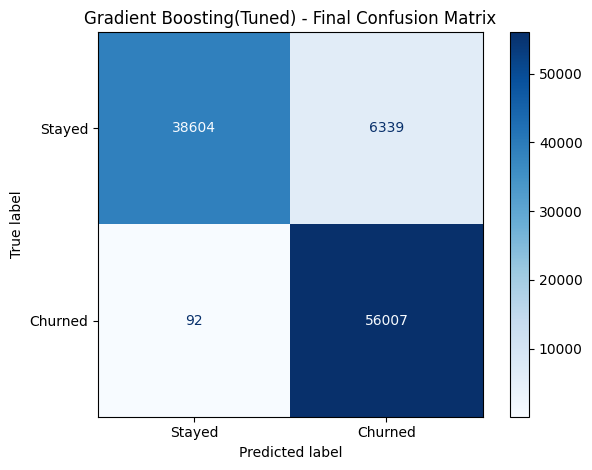

In [115]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_final,
    display_labels=['Stayed', 'Churned'],
    cmap='Blues',
    values_format='d'
)

plt.title(f'{selected_model_name} - Final Confusion Matrix')
plt.tight_layout()
plt.show()

In [116]:
final_classification_report = classification_report(
    y_test,
    y_pred_final,
    target_names=['Stayed', 'Churned'],
    digits=4
)

print(f'{selected_model_name} - Final Classification Report\n')

print(final_classification_report)

Gradient Boosting(Tuned) - Final Classification Report

              precision    recall  f1-score   support

      Stayed     0.9976    0.8590    0.9231     44943
     Churned     0.8983    0.9984    0.9457     56099

    accuracy                         0.9364    101042
   macro avg     0.9480    0.9287    0.9344    101042
weighted avg     0.9425    0.9364    0.9357    101042



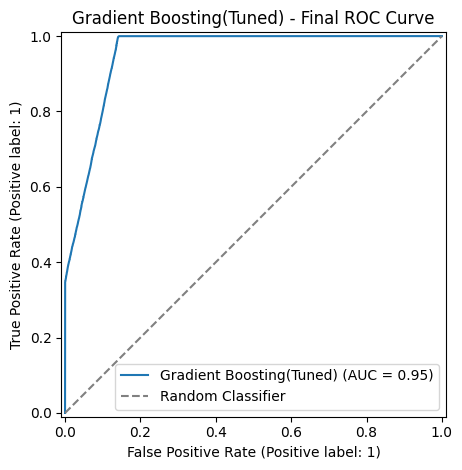

In [117]:
RocCurveDisplay.from_predictions(
    y_test,
    y_prob_final,
    name=selected_model_name
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='gray',
    label='Random Classifier'
)

plt.title(f'{selected_model_name} - Final ROC Curve')
plt.legend()
plt.tight_layout()
plt.show()

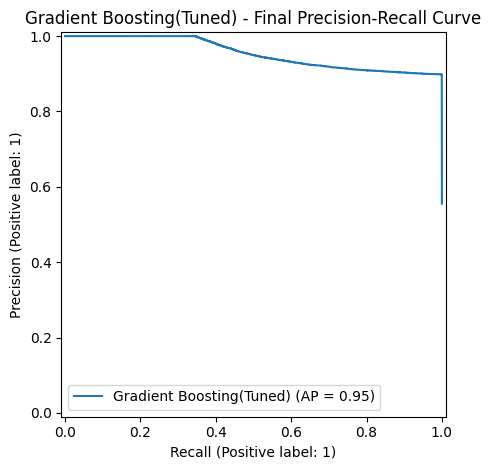

In [118]:
PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob_final,
    name=selected_model_name
)

plt.title(f'{selected_model_name} - Final Precision-Recall Curve')
plt.tight_layout()
plt.show()

# Model Deployment & Export

In [119]:
import joblib
import os
import json
import sklearn

In [120]:
deployment_dir = "deployment"

os.makedirs(deployment_dir, exist_ok=True)

print("Deployment folder created successfully!")

Deployment folder created successfully!


In [121]:
model_path = os.path.join(
    deployment_dir,
    "customer_churn_model.joblib"
)

joblib.dump(
    selected_model,
    model_path
)

print("Model saved successfully!")

Model saved successfully!


In [122]:
feature_schema = {}

for column in X.columns:

    if column in numerical_cols:
        feature_schema[column] = "number"

    else:
        feature_schema[column] = "string"


with open(
    os.path.join(deployment_dir, "feature_schema.json"),
    "w"
) as file:

    json.dump(feature_schema, file, indent=4)

print("Feature schema saved successfully!")

Feature schema saved successfully!


In [123]:
metadata = {
    "project_name": "Customer Churn Prediction",

    "model_name": selected_model_name,

    "target_column": "Churn",

    "prediction_classes": {
        "0": "Stayed",
        "1": "Churned"
    },

    "features": X.columns.tolist(),

    "number_of_features": len(X.columns),

    "evaluation_metrics": {
        key: float(value)
        for key, value in final_results.items()
    },

    "threshold": 0.5,

    "sklearn_version": sklearn.__version__,
}


with open(
    os.path.join(deployment_dir, "model_metadata.json"),
    "w"
) as file:

    json.dump(metadata, file, indent=4)

print("Metadata saved successfully!")

Metadata saved successfully!


In [124]:
loaded_model = joblib.load(model_path)

sample_data = X_test.head(5)

predictions = loaded_model.predict(sample_data)

probabilities = loaded_model.predict_proba(sample_data)[:, 1]


test_results = pd.DataFrame({
    "Prediction": predictions,
    "Churn Probability": probabilities
})

display(test_results)

,Prediction,Churn Probability
0,1,0.835715
1,1,0.854252
2,0,0.001666
3,1,0.995226
4,1,0.844627


In [125]:
original_predictions = selected_model.predict(sample_data)

loaded_predictions = loaded_model.predict(sample_data)

assert np.array_equal(
    original_predictions,
    loaded_predictions
)

print("Export Test Passed Successfully!")

Export Test Passed Successfully!
